# Системы поддержки принятия решений

**Упражнения 4.1–4.10. Сетевая оптимизация**

Практическая работа по главе 4. Математические модели, сетевые алгоритмы и проверка оптимальности решений.


In [1]:
import itertools
import pyomo.environ as pyo
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "figure.dpi": 120,
    "figure.figsize": (10, 5.8),
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 60)
pd.set_option("display.precision", 2)
solver = pyo.SolverFactory("highs")
if not solver.available(exception_flag=False):
    raise RuntimeError("Для запуска требуется пакет highspy: pip install highspy")
solver.options["mip_rel_gap"] = 0.0


def solve_model(model):
    result = solver.solve(model)
    pyo.assert_optimal_termination(result)
    return result


def draw_graph(graph, pos=None, edge_labels=None, highlight_edges=None,
               title="", node_colors=None):
    if pos is None:
        pos = nx.spring_layout(graph, seed=41)
    selected = set(highlight_edges or [])
    if not graph.is_directed():
        selected |= {(v, u) for u, v in list(selected)}
    edge_colors = ["#ba5b35" if edge in selected else "#98a5b2" for edge in graph.edges]
    widths = [2.8 if edge in selected else 1.3 for edge in graph.edges]
    fig, ax = plt.subplots(figsize=(11, 6.4))
    nx.draw(graph, pos, ax=ax, with_labels=True,
            node_color=node_colors if node_colors is not None else "#dce8f0",
            node_size=1050, font_size=10, font_color="#172d40",
            edge_color=edge_colors, width=widths, arrows=graph.is_directed(),
            edgecolors="#4b6a83", linewidths=1.2,
            **({"arrowsize": 18} if graph.is_directed() else {}))
    if edge_labels is None:
        edge_labels = nx.get_edge_attributes(graph, "weight")
        if not edge_labels:
            edge_labels = nx.get_edge_attributes(graph, "capacity")
    if edge_labels:
        nx.draw_networkx_edge_labels(graph, pos, edge_labels=edge_labels,
                                    font_size=9, rotate=False, ax=ax,
                                    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
    ax.set_title(title, fontsize=14, pad=20)
    ax.margins(0.15)
    plt.tight_layout()
    plt.show()


## Задача 4.1

### Условие

В заданный день в указанных местах проводятся пять мероприятий с известным временем начала и продолжительностью (в часах), как указано ниже слева.

| event | location | start | duration |
|:---:|:---:|---:|---:|
| a | A | 10 | 2 |
| b | B | 11 | 1 |
| c | C | 13 | 1 |
| d | D | 15 | 1 |
| e | E | 16 | 2 |

| | A | B | C | D | E |
|:---:|---:|---:|---:|---:|---:|
| A | 0 | 2 | 3 | 4 | 3 |
| B | 2 | 0 | 1 | 3 | 4 |
| C | 3 | 1 | 0 | 1 | 3 |
| D | 4 | 3 | 1 | 0 | 1 |
| E | 3 | 4 | 3 | 1 | 0 |

Каждому мероприятию требуется судья, и один и тот же судья может присутствовать на разных мероприятиях при условии, что они могут добраться с одного на другое вовремя. Время в пути (в часах) между местами проведения мероприятий также известно, как указано выше справа.

(a) Постройте сеть допустимых связей, где каждый узел — это мероприятие, и найдите оптимальное решение задачи минимизации количества необходимых судей. Можете ли вы предложить общую процедуру для задач большего размера, которая всегда определяла бы оптимальное решение?

(b) Рассмотрим теперь другую модель, в которой каждое мероприятие представляет собой дугу, соединяющую начальный узел с конечным узлом. В этой сети конечные узлы соединяются с начальными узлами мероприятий, которые могут следовать далее. Сформулируйте задачу из предыдущего вопроса как задачу MILO и решите её. Можно ли решить её, используя только решатель ЛО?

(c) Как можно было бы изменить модель ЛО из предыдущего вопроса, если цель состоит в том, чтобы минимизировать общее количество часов, отработанных судьями, с момента начала первого мероприятия до конца последнего мероприятия, в котором участвует каждый из них? Можно ли решить её, используя только решатель ЛО?

(d) Что произойдет, если мы ограничим общее рабочее время (с момента начала их первых мероприятий до конца их последних мероприятий), затрачиваемое всеми участвующими судьями, до 10 или менее, но при этом по-прежнему хотим минимизировать количество привлекаемых судей? Можно ли решить её, используя только решатель ЛО?

(e) Что произойдет, если работа каждого отдельного судьи должна составлять не более 6 часов, при минимизации либо количества привлекаемых судей, либо общего рабочего времени?

### Дано

Исходные числа приведены в двух таблицах условия. Для мероприятия $i$ обозначим начало через $s_i$, длительность через $d_i$, окончание через $f_i=s_i+d_i$, а время переезда из $i$ в $j$ через $t_{ij}$.

| Мероприятие | Начало | Окончание | Длительность, ч |
|:---:|---:|---:|---:|
| a | 10 | 12 | 2 |
| b | 11 | 12 | 1 |
| c | 13 | 14 | 1 |
| d | 15 | 16 | 1 |
| e | 16 | 18 | 2 |

Общая длительность самих мероприятий равна $7$ ч. В рабочее время судьи входят переезды и ожидание между его первым и последним мероприятиями; дорога до первого и после последнего мероприятия не учитывается.

### Математическая модель

**(a) Минимальное покрытие путями.** В DAG проводим дугу $i\to j$ тогда и только тогда, когда $f_i+t_{ij}\le s_j$. Каждый путь задаёт маршрут одного судьи. Раздвоим множество мероприятий на левую и правую доли и перенесём допустимые переходы в двудольный граф. Если максимальное паросочетание содержит $m$ рёбер, минимум судей равен $|V|-m$. Паросочетание находится единичным максимальным потоком. Это точная полиномиальная процедура для любого такого DAG.

**(b) Сеть с мероприятиями-дугами.** Разделим каждое мероприятие на вершины $i^-$ и $i^+$. Введём обязательную дугу $(i^-,i^+)$ с потоком ровно $1$, переходы $(i^+,j^-)$, дуги $(S,i^-)$, $(i^+,T)$ и замыкающую дугу $(T,S)$. Переменная $x_{uv}$ — число судей на дуге. MILO-модель:

$$\min x_{TS},\qquad
\sum_{u:(u,v)\in A}x_{uv}=\sum_{w:(v,w)\in A}x_{vw}\quad(v\in N),$$
$$x_{i^-i^+}=1,\quad 0\le x_{uv}\le1\ ((u,v)\ne(T,S)),\quad 0\le x_{TS}\le5,\quad x_{uv}\in\mathbb Z.$$

Матрица балансов ориентированной сети полностью унимодулярна. При целых границах LP-релаксация имеет целочисленную оптимальную вершину, поэтому достаточно решателя ЛО.

**(c) Минимум часов.** Заменим цель на

$$\min H(x),\qquad H(x)=\sum_i d_i x_{i^-i^+}+\sum_{(i,j)\in E}(s_j-f_i)x_{i^+j^-}.$$

Вдоль каждого маршрута сумма телескопируется в $f_{\rm last}-s_{\rm first}$. Меняется только цель; полная унимодулярность сохраняется, и достаточно ЛО.

**(d) Общий лимит.** Минимизируем $x_{TS}$ при дополнительном ограничении $H(x)\le10$. Произвольная дополнительная строка не сохраняет гарантию целочисленности сетевого многогранника. Ниже MILO и LP-релаксация сравниваются численно.

**(e) Лимит на каждого судью.** Пусть $\mathcal P_6$ — все допустимые пути $p$ с размахом $h_p=f_{\rm last(p)}-s_{\rm first(p)}\le6$, включая одноэлементные. Переменная $z_p\in\{0,1\}$ выбирает маршрут. Решаем две задачи:

$$\sum_{p\in\mathcal P_6:i\in p}z_p=1\quad(i\in V),\qquad
\min\sum_pz_p\quad\text{или}\quad\min\sum_ph_pz_p.$$

Это модель разбиения на допустимые маршруты. Для неё общей гарантии полной унимодулярности нет; используем целочисленный решатель. Перебор путей удобен для пяти мероприятий, но для больших примеров может потребоваться генерация столбцов.

### Найти

По пунктам (a)–(e): оптимальные маршруты, число судей и суммарные часы; для (b)–(d) — возможность использования LP-релаксации; для (e) — решения при обеих целевых функциях.

### Решение

Сначала строим граф допустимых переходов и находим минимальное покрытие путями с помощью максимального потока.

,Судья,Маршрут,Начало,Конец,"Рабочее время, ч"
0,1,a → e,10,18,8
1,2,b → c → d,11,16,5


,Переход,"Переезд, ч","Переезд и ожидание, ч"
0,a → e,3,4
1,b → c,1,1
2,b → d,3,3
3,b → e,4,4
4,c → d,1,1


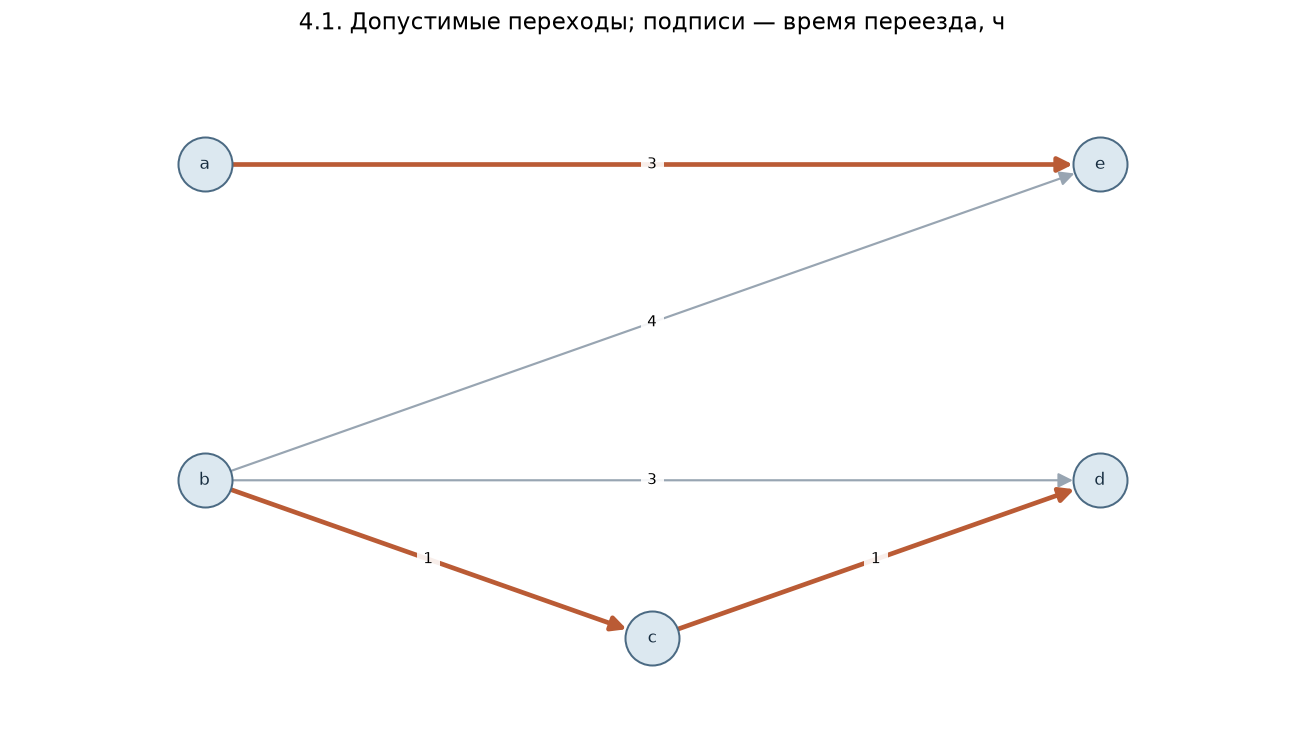

In [2]:
events_41 = pd.DataFrame({
    "Место": list("ABCDE"),
    "Начало": [10, 11, 13, 15, 16],
    "Длительность": [2, 1, 1, 1, 2]
}, index=list("abcde"))
events_41["Конец"] = events_41["Начало"] + events_41["Длительность"]
travel_41 = pd.DataFrame(
    [[0, 2, 3, 4, 3], [2, 0, 1, 3, 4], [3, 1, 0, 1, 3],
     [4, 3, 1, 0, 1], [3, 4, 3, 1, 0]],
    index=list("ABCDE"), columns=list("ABCDE")
)
event_graph_41 = nx.DiGraph()
event_graph_41.add_nodes_from(events_41.index)
for first in events_41.index:
    for second in events_41.index:
        travel_time = int(travel_41.loc[events_41.loc[first, "Место"], events_41.loc[second, "Место"]])
        if events_41.loc[first, "Конец"] + travel_time <= events_41.loc[second, "Начало"]:
            event_graph_41.add_edge(first, second, weight=travel_time,
                                    gap=int(events_41.loc[second, "Начало"] - events_41.loc[first, "Конец"]))
assert nx.is_directed_acyclic_graph(event_graph_41)
matching_network_41 = nx.DiGraph()
for event in events_41.index:
    matching_network_41.add_edge("S", event + "_L", capacity=1)
    matching_network_41.add_edge(event + "_R", "T", capacity=1)
for first, second in event_graph_41.edges:
    matching_network_41.add_edge(first + "_L", second + "_R", capacity=1)
matching_size_41, matching_flow_41 = nx.maximum_flow(
    matching_network_41, "S", "T", flow_func=nx.algorithms.flow.edmonds_karp
)
matched_edges_41 = [(i, j) for i, j in event_graph_41.edges if matching_flow_41[i + "_L"][j + "_R"] > 0]

def judge_routes_41(selected_edges):
    successors = dict(selected_edges)
    starts = [event for event in events_41.index if event not in successors.values()]
    routes = []
    for first in starts:
        route = [first]
        while route[-1] in successors:
            route.append(successors[route[-1]])
        routes.append(route)
    return routes

def judge_table_41(routes):
    return pd.DataFrame([
        {"Судья": number, "Маршрут": " → ".join(route),
         "Начало": events_41.loc[route[0], "Начало"],
         "Конец": events_41.loc[route[-1], "Конец"],
         "Рабочее время, ч": events_41.loc[route[-1], "Конец"] - events_41.loc[route[0], "Начало"]}
        for number, route in enumerate(routes, 1)
    ])

routes_41a = judge_routes_41(matched_edges_41)
display(judge_table_41(routes_41a))
display(pd.DataFrame([
    {"Переход": f"{i} → {j}", "Переезд, ч": data["weight"], "Переезд и ожидание, ч": data["gap"]}
    for i, j, data in event_graph_41.edges(data=True)
]))
draw_graph(event_graph_41,
           pos={"a": (0, 1), "b": (0, -1), "c": (2, -2), "d": (4, -1), "e": (4, 1)},
           edge_labels=nx.get_edge_attributes(event_graph_41, "weight"),
           highlight_edges=matched_edges_41, title="4.1. Допустимые переходы; подписи — время переезда, ч")
assert len(routes_41a) == len(events_41) - matching_size_41 == 2

Сеть следующей модели содержит обязательные дуги мероприятий. На рисунке показаны эти дуги и допустимые переходы; технические вершины $S,T$ с примыкающими дугами опущены для читаемости. Замыкающая дуга $T\to S$ используется в модели для подсчёта судей. Подпись дуги мероприятия — её длительность, перехода — переезд вместе с ожиданием; стоимости технических дуг равны нулю.

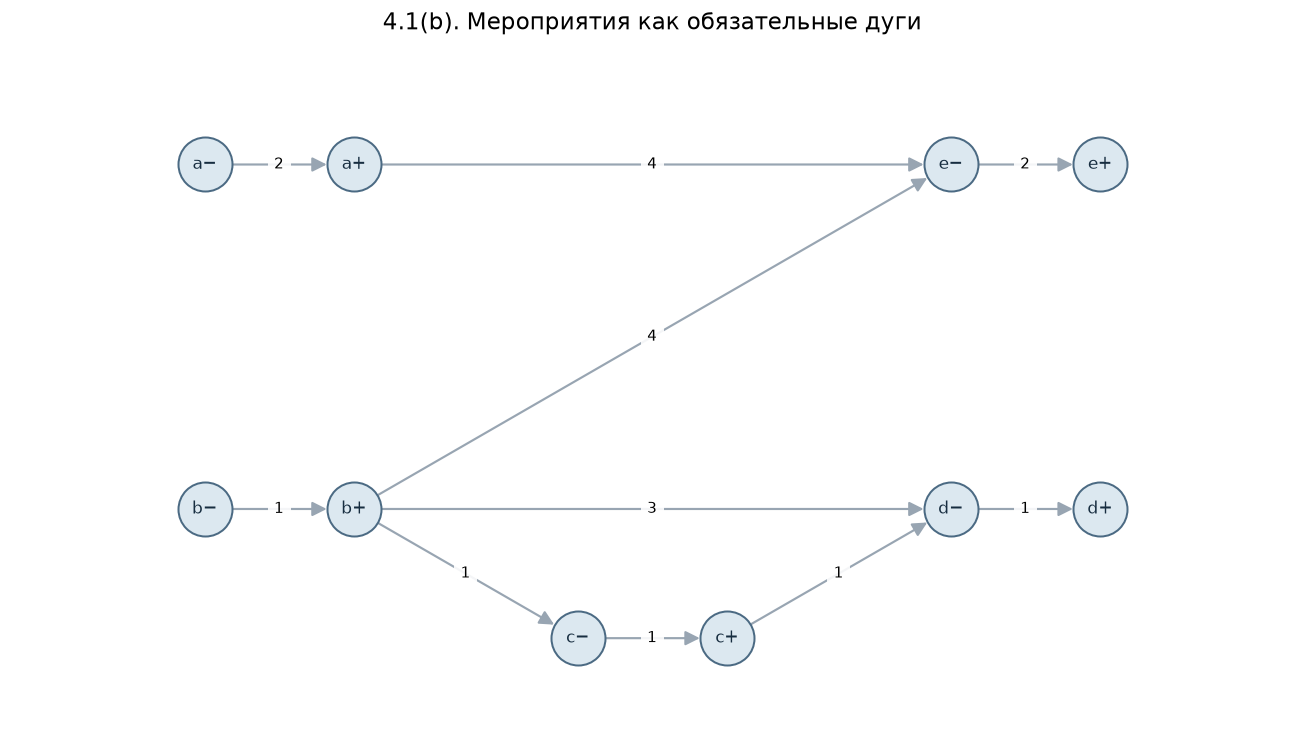

,Вариант,Число судей,"Общее время, ч"
0,"b: минимум судей, MILO",2.00,13.0
1,"b: минимум судей, LP",2.00,13.0
2,"c: минимум часов, LP",5.00,7.0
3,"d: общий лимит 10 ч, MILO",3.00,9.0
4,"d: общий лимит 10 ч, LP",2.75,10.0


,Вариант,Судья,Маршрут,Начало,Конец,"Рабочее время, ч"
0,"b: минимум судей, MILO",1,a → e,10,18,8
1,"b: минимум судей, MILO",2,b → c → d,11,16,5


,Вариант,Судья,Маршрут,Начало,Конец,"Рабочее время, ч"
0,"c: минимум часов, LP",1,a,10,12,2
1,"c: минимум часов, LP",2,b,11,12,1
2,"c: минимум часов, LP",3,c,13,14,1
3,"c: минимум часов, LP",4,d,15,16,1
4,"c: минимум часов, LP",5,e,16,18,2


,Вариант,Судья,Маршрут,Начало,Конец,"Рабочее время, ч"
0,"d: общий лимит 10 ч, MILO",1,a,10,12,2
1,"d: общий лимит 10 ч, MILO",2,b → c → d,11,16,5
2,"d: общий лимит 10 ч, MILO",3,e,16,18,2


,Переход в LP,Поток
0,a → e,0.25
1,b → c,1.00
2,b → d,0.00
3,b → e,0.00
4,c → d,1.00


In [3]:
split_graph_41 = nx.DiGraph()
for event in events_41.index:
    split_graph_41.add_edge("S", event + "−", lower=0, upper=1, hours=0)
    split_graph_41.add_edge(event + "−", event + "+", lower=1, upper=1,
                            hours=int(events_41.loc[event, "Длительность"]))
    split_graph_41.add_edge(event + "+", "T", lower=0, upper=1, hours=0)
for first, second, data in event_graph_41.edges(data=True):
    split_graph_41.add_edge(first + "+", second + "−", lower=0, upper=1, hours=data["gap"])
split_graph_41.add_edge("T", "S", lower=0, upper=5, hours=0)

def build_judge_model_41(objective="count", integer=True, hours_limit=None):
    model = pyo.ConcreteModel()
    model.nodes = pyo.Set(initialize=list(split_graph_41.nodes))
    model.arcs = pyo.Set(initialize=list(split_graph_41.edges), dimen=2)
    model.flow = pyo.Var(model.arcs, domain=pyo.NonNegativeIntegers if integer else pyo.NonNegativeReals,
                         bounds=lambda m, u, v: (split_graph_41[u][v]["lower"], split_graph_41[u][v]["upper"]))
    model.balance = pyo.Constraint(model.nodes, rule=lambda m, v:
        sum(m.flow[u, v] for u in split_graph_41.predecessors(v)) ==
        sum(m.flow[v, w] for w in split_graph_41.successors(v)))
    model.hours = pyo.Expression(expr=sum(split_graph_41[u][v]["hours"] * model.flow[u, v] for u, v in model.arcs))
    model.judges = pyo.Expression(expr=model.flow["T", "S"])
    if hours_limit is not None:
        model.hours_bound = pyo.Constraint(expr=model.hours <= hours_limit)
    model.objective = pyo.Objective(expr=model.judges if objective == "count" else model.hours)
    return model

split_positions_41 = {"S": (-1, 0), "T": (7, 0)}
for event, (x, y) in {"a": (0, 2), "b": (0, -2), "c": (2, -3.5), "d": (4, -2), "e": (4, 2)}.items():
    split_positions_41[event + "−"] = (x, y)
    split_positions_41[event + "+"] = (x + 0.8, y)
split_picture_41 = split_graph_41.copy()
split_picture_41.remove_nodes_from(["S", "T"])
draw_graph(split_picture_41, pos=split_positions_41,
           edge_labels=nx.get_edge_attributes(split_picture_41, "hours"),
           title="4.1(b). Мероприятия как обязательные дуги")

judge_models_41 = {}
judge_summary_41 = []
for label, objective, integer, limit in [
    ("b: минимум судей, MILO", "count", True, None),
    ("b: минимум судей, LP", "count", False, None),
    ("c: минимум часов, LP", "hours", False, None),
    ("d: общий лимит 10 ч, MILO", "count", True, 10),
    ("d: общий лимит 10 ч, LP", "count", False, 10)
]:
    model = build_judge_model_41(objective, integer, limit)
    solve_model(model)
    judge_models_41[label] = model
    judge_summary_41.append({"Вариант": label, "Число судей": pyo.value(model.judges),
                            "Общее время, ч": pyo.value(model.hours)})
display(pd.DataFrame(judge_summary_41))
for label in ["b: минимум судей, MILO", "c: минимум часов, LP", "d: общий лимит 10 ч, MILO"]:
    model = judge_models_41[label]
    selected = [(i, j) for i, j in event_graph_41.edges if pyo.value(model.flow[i + "+", j + "−"]) > 0.5]
    result = judge_table_41(judge_routes_41(selected))
    result.insert(0, "Вариант", label)
    display(result)
relaxed_model_41 = judge_models_41["d: общий лимит 10 ч, LP"]
display(pd.DataFrame([
    {"Переход в LP": f"{i} → {j}", "Поток": max(0.0, pyo.value(relaxed_model_41.flow[i + "+", j + "−"]))}
    for i, j in event_graph_41.edges
]))
assert np.isclose(pyo.value(judge_models_41["b: минимум судей, LP"].judges), 2)
assert np.isclose(pyo.value(judge_models_41["c: минимум часов, LP"].hours), 7)
assert np.isclose(pyo.value(judge_models_41["d: общий лимит 10 ч, MILO"].judges), 3)
assert np.isclose(pyo.value(relaxed_model_41.judges), 2.75)

Для индивидуального лимита $6$ ч перечислим допустимые маршруты и решим две модели разбиения. Обязательное покрытие каждого мероприятия ровно один раз исключает пропуски и двойное назначение.

In [4]:
all_routes_41 = [[event] for event in events_41.index]
for first in events_41.index:
    for last in events_41.index:
        if first != last:
            all_routes_41.extend(nx.all_simple_paths(event_graph_41, first, last))
routes_under_6_41 = [route for route in all_routes_41
                     if events_41.loc[route[-1], "Конец"] - events_41.loc[route[0], "Начало"] <= 6]
route_hours_41 = [int(events_41.loc[route[-1], "Конец"] - events_41.loc[route[0], "Начало"])
                  for route in routes_under_6_41]
display(pd.DataFrame({"Допустимый маршрут": [" → ".join(route) for route in routes_under_6_41],
                      "Рабочее время, ч": route_hours_41}))
individual_summary_41 = []
for objective in ["count", "hours"]:
    route_model = pyo.ConcreteModel()
    route_model.paths = pyo.RangeSet(0, len(routes_under_6_41) - 1)
    route_model.selected = pyo.Var(route_model.paths, domain=pyo.Binary)
    route_model.cover = pyo.Constraint(list(events_41.index), rule=lambda m, event:
        sum(m.selected[p] for p in m.paths if event in routes_under_6_41[p]) == 1)
    route_model.objective = pyo.Objective(expr=sum(
        (1 if objective == "count" else route_hours_41[p]) * route_model.selected[p] for p in route_model.paths))
    solve_model(route_model)
    chosen_routes = [routes_under_6_41[p] for p in route_model.paths if pyo.value(route_model.selected[p]) > 0.5]
    result = judge_table_41(chosen_routes)
    result.insert(0, "Цель", "Минимум судей" if objective == "count" else "Минимум часов")
    display(result)
    individual_summary_41.append((len(result), int(result["Рабочее время, ч"].sum())))
    assert max(result["Рабочее время, ч"]) <= 6
    assert sorted(event for route in chosen_routes for event in route) == sorted(events_41.index)
assert individual_summary_41 == [(3, 9), (5, 7)]

,Допустимый маршрут,"Рабочее время, ч"
0,a,2
1,b,1
2,c,1
3,d,1
4,e,2
5,b → c,3
6,b → c → d,5
7,b → d,5
8,c → d,3


,Цель,Судья,Маршрут,Начало,Конец,"Рабочее время, ч"
0,Минимум судей,1,a,10,12,2
1,Минимум судей,2,e,16,18,2
2,Минимум судей,3,b → c → d,11,16,5


,Цель,Судья,Маршрут,Начало,Конец,"Рабочее время, ч"
0,Минимум часов,1,a,10,12,2
1,Минимум часов,2,b,11,12,1
2,Минимум часов,3,c,13,14,1
3,Минимум часов,4,d,15,16,1
4,Минимум часов,5,e,16,18,2


### Ответ

- **(a)** Допустимые переходы: $a\to e$, $b\to c$, $b\to d$, $b\to e$, $c\to d$. Максимальное паросочетание имеет мощность $3$, поэтому нужно **$5-3=2$ судьи**: маршруты $a\to e$ и $b\to c\to d$. Общий точный метод — максимальный поток в двудольной сети и восстановление минимального покрытия DAG путями.
- **(b)** MILO даёт те же **2 судьи**, с рабочим временем $8+5=13$ ч. **ЛО достаточно:** матрица сетевых балансов полностью унимодулярна, границы целые.
- **(c)** Минимум — **7 ч**, по одному судье на каждое мероприятие, то есть **5 судей**. Это нижняя граница, равная сумме длительностей мероприятий; каждый допустимый переход добавляет положительное время. **ЛО достаточно**, поскольку изменена только цель.
- **(d)** При общем лимите $10$ ч нужны **3 судьи**: $a$, $b\to c\to d$, $e$; всего $2+5+2=9$ ч. Два судьи дали бы $13$ ч. **ЛО недостаточно:** релаксация даёт $2{,}75$ судьи при $10$ ч. Например, переходы $b\to c$ и $c\to d$ имеют поток $1$, а $a\to e$ — $0{,}25$. Такой дробный результат не является расписанием.
- **(e)** При лимите $6$ ч на судью **минимум судей равен 3**: $a$, $b\to c\to d$, $e$; индивидуальные времена $2,5,2$ ч. При минимизации общего времени оптимальны **7 ч и 5 судей** с отдельным мероприятием у каждого. Для общего случая ограничения на длительность маршрутов требуют целочисленной модели; сетевую гарантию из (b) автоматически переносить нельзя.

## Задача 4.2

### Условие

Рассмотрим сеть компьютеров, соединенных таким образом, что между каждой парой компьютеров существует путь, хотя не все компьютеры соединены напрямую. Предполагается, что время, необходимое сообщению для прохождения между двумя соседними компьютерами, известно. Компьютеры могут пересылать сообщения, и поэтому сообщения могут проходить путь до достижения пункта назначения. Цель состоит в том, чтобы отправить сообщение на все компьютеры так, чтобы каждый компьютер получил сообщение в кратчайшие возможные сроки. Как следует маршрутизировать такое сообщение в сети? Предположим, что временем, затрачиваемым на обработку сообщения перед пересылкой, можно пренебречь.

### Дано

В условии нет конкретной сети и источника. Для воспроизводимой демонстрации выбрана следующая связная неориентированная сеть из шести компьютеров; источник сообщения — $A$. Задержки положительные и выражены в миллисекундах. Значения заданы явно и одинаковы при каждом запуске.

| Соединение | Задержка, мс | Соединение | Задержка, мс |
|:---:|---:|:---:|---:|
| A–B | 4 | C–D | 8 |
| A–C | 2 | C–E | 10 |
| B–C | 1 | D–E | 2 |
| B–D | 5 | D–F | 6 |
| E–F | 3 | | |

Предполагается, что полученное сообщение можно одновременно переслать по нескольким соединениям; конкуренция за каналы не моделируется.

### Математическая модель

Пусть $G=(V,E)$, источник $s=A$, а $\ell_{uv}\ge0$ — задержка. Для каждого узла требуется минимизировать момент получения сообщения:

$$d(v)=\min_{P:s\leadsto v}\sum_{e\in P}\ell_e.$$

Расстояния удовлетворяют $d(s)=0$ и $d(v)\le d(u)+\ell_{uv}$ для каждой ориентированной версии ребра. Их также можно получить из LP $\max\sum_{v\ne s}d(v)$ при этих ограничениях. Выбрав для каждого $v\ne s$ одного предшественника $p(v)$, для которого $d(v)=d(p(v))+\ell_{p(v),v}$, получаем **дерево кратчайших путей (SPT)**. В нашем примере задержки строго положительны, поэтому расстояние вдоль выбранных дуг строго возрастает и циклы невозможны.

Алгоритм Дейкстры одновременно находит кратчайшие расстояния и пути от источника. Пересылка по SPT обеспечивает каждому компьютеру его индивидуально минимальное время получения. Минимизация суммы длин рёбер остова решала бы другую задачу и не гарантировала бы минимальных задержек от источника.

### Найти

Дерево маршрутизации, маршрут до каждого компьютера и минимальное время доставки сообщения.

### Решение

,Компьютер,Предшественник,Маршрут,"Доставка, мс"
0,A,—,A,0
1,B,C,A → C → B,3
2,C,A,A → C,2
3,D,B,A → C → B → D,8
4,E,D,A → C → B → D → E,10
5,F,E,A → C → B → D → E → F,13


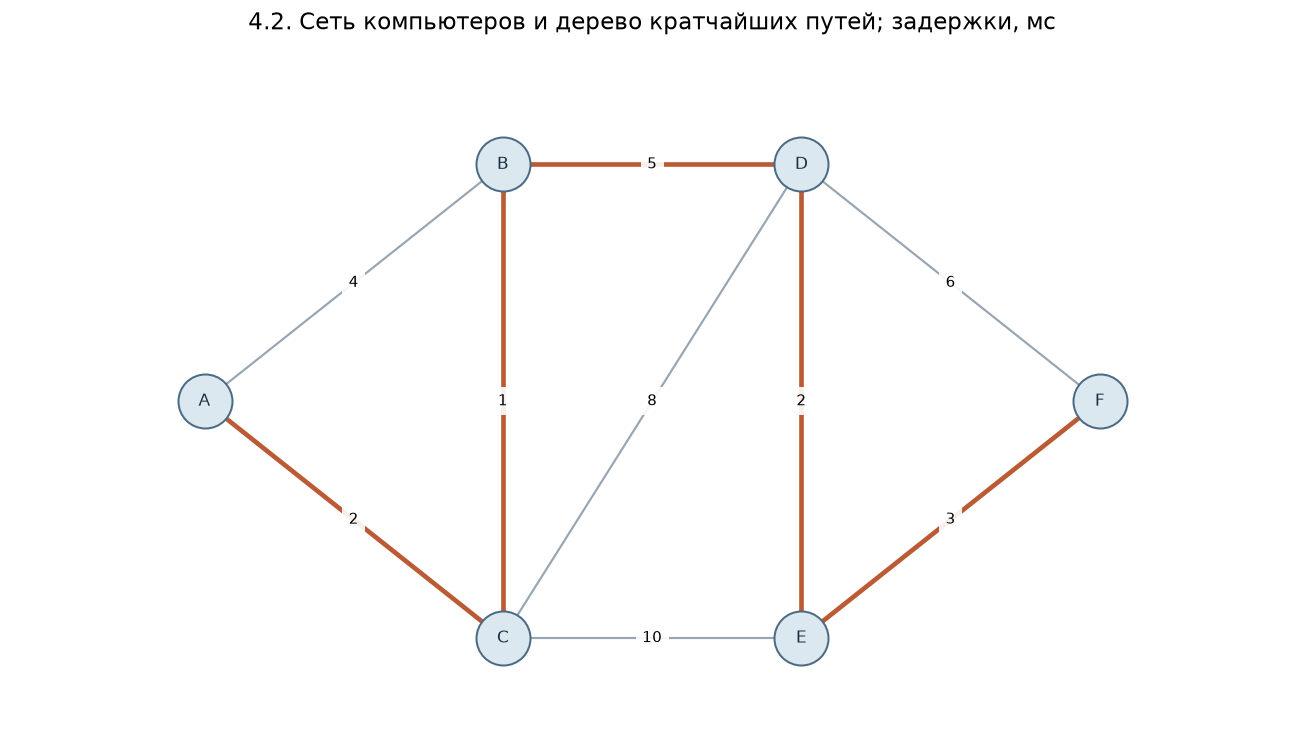

In [5]:
computer_graph_42 = nx.Graph()
computer_graph_42.add_weighted_edges_from([
    ("A", "B", 4), ("A", "C", 2), ("B", "C", 1), ("B", "D", 5),
    ("C", "D", 8), ("C", "E", 10), ("D", "E", 2), ("D", "F", 6), ("E", "F", 3)
])
distances_42, paths_42 = nx.single_source_dijkstra(computer_graph_42, "A", weight="weight")
shortest_tree_42 = nx.DiGraph()
shortest_tree_42.add_nodes_from(computer_graph_42.nodes)
for target, path in paths_42.items():
    if target != "A":
        first, second = path[-2:]
        shortest_tree_42.add_edge(first, second, weight=computer_graph_42[first][second]["weight"])
routing_table_42 = pd.DataFrame([
    {"Компьютер": target, "Предшественник": paths_42[target][-2] if target != "A" else "—",
     "Маршрут": " → ".join(paths_42[target]), "Доставка, мс": distances_42[target]}
    for target in sorted(computer_graph_42.nodes)
])
display(routing_table_42)
positions_42 = {"A": (0, 1), "B": (1.5, 2), "C": (1.5, 0), "D": (3, 2), "E": (3, 0), "F": (4.5, 1)}
draw_graph(computer_graph_42, pos=positions_42,
           edge_labels=nx.get_edge_attributes(computer_graph_42, "weight"),
           highlight_edges=list(shortest_tree_42.edges),
           title="4.2. Сеть компьютеров и дерево кратчайших путей; задержки, мс")
assert nx.is_arborescence(shortest_tree_42)
assert distances_42 == {"A": 0, "C": 2, "B": 3, "D": 8, "E": 10, "F": 13}
assert all(nx.path_weight(computer_graph_42, paths_42[v], "weight") == distances_42[v]
           for v in computer_graph_42.nodes)

### Ответ

1. Следует передавать сообщение по **дереву кратчайших путей от исходного компьютера**, найденному алгоритмом Дейкстры.
2. Для демонстрационного примера дерево состоит из дуг $A\to C$, $C\to B$, $B\to D$, $D\to E$, $E\to F$.
3. Минимальные времена доставки: $A:0$, $B:3$, $C:2$, $D:8$, $E:10$, $F:13$ мс. Все компьютеры получат сообщение через **13 мс**; каждый получает его в свой минимально возможный момент.

## Задача 4.3

### Условие

Рассмотрим человека, который только что купил (в момент времени 0) новый автомобиль за 12 000 долларов. Стоимость содержания автомобиля в течение одного года зависит от его возраста на начало года, как описано в таблице ниже. Чтобы избежать высоких затрат на содержание, связанных со старым автомобилем, можно сдать автомобиль в трейд-ин и купить новый. Цена, полученная при трейд-ине, зависит от возраста автомобиля на момент трейд-ина (см. таблицу ниже). Предположим, что в любой момент времени покупка нового автомобиля стоит 12 000 долларов. Цель состоит в том, чтобы минимизировать чистые затраты (затраты на покупку + затраты на содержание — деньги, полученные при трейд-ине) в течение следующих пяти лет.

| Age of car (years) | Annual maintenance costs (USD) | Trade-in price (USD) |
|---:|---:|---:|
| 0 | 2,000 | 7,000 |
| 1 | 4,000 | 6,000 |
| 2 | 5,000 | 2,000 |
| 3 | 9,000 | 1,000 |
| 4 | 12,000 | 0 |

Сформулируйте эту задачу как задачу о кратчайшем пути и решите её, используя алгоритм на ваш выбор.

### Дано

Покупка стоит $P=12\,000$ долларов. Горизонт — пять лет. Исходная таблица переписана без сдвига возрастов:

| Возраст, лет | Содержание за следующий год, долл. | Трейд-ин в этом возрасте, долл. |
|---:|---:|---:|
| 0 | 2 000 | 7 000 |
| 1 | 4 000 | 6 000 |
| 2 | 5 000 | 2 000 |
| 3 | 9 000 | 1 000 |
| 4 | 12 000 | 0 |

**Граничное условие.** В PDF не предписана продажа автомобиля в конце пятого года и не указана цена трейд-ин пятилетнего автомобиля. Основной расчёт учитывает реальные покупки, содержание и трейд-ин при заменах внутри горизонта; в момент $5$ автомобиль остаётся у владельца. Начальная покупка включена в общую стоимость, хотя её исключение как уже понесённой затраты не изменяет оптимального графика. Ниже отдельно показано, как меняется ответ при дополнительном условии обязательной продажи в конце горизонта.

### Математическая модель

Вершины DAG — моменты $0,1,\ldots,5$. Дуга $i\to j$, $i<j$, означает покупку нового автомобиля в момент $i$ и его использование до момента $j$. Обозначим расходы на содержание в возрасте $a$ через $m_a$, цену трейд-ин — через $r_a$. Стоимость дуги:

$$c_{ij}=P+\sum_{a=0}^{j-i-1}m_a-\begin{cases}r_{j-i},&j<5,\\0,&j=5.\end{cases}$$

На промежуточной вершине стоимость старого автомобиля вычитается на входящей дуге, а покупка нового учитывается на исходящей; двойного учёта нет. На дугах, приходящих в $5$, продажа не предполагается.

Ищем кратчайший путь $0\leadsto5$. Эквивалентная потоковая модель имеет вид

$$\min\sum_{(i,j)}c_{ij}x_{ij},\qquad
\sum_jx_{vj}-\sum_ix_{iv}=\begin{cases}1,&v=0,\\-1,&v=5,\\0,&\text{иначе},\end{cases}\quad x_{ij}\ge0.$$

Это сетевой LP с целочисленной оптимальной вершиной. Для DAG достаточно динамического программирования в топологическом порядке:

$$D(0)=0,\qquad D(j)=\min_{i<j}\{D(i)+c_{ij}\}.$$

### Найти

Минимальные чистые расходы за пять лет, моменты замены автомобиля и разложение общей стоимости на покупки, содержание и выручку от трейд-ин.

### Решение

,Покупка в году,Использовать до года,"Срок, лет","Стоимость дуги, долл."
0,0,1,1,8000
1,0,2,2,16000
2,0,3,3,22000
3,0,4,4,32000
4,0,5,5,44000
5,1,2,1,8000
6,1,3,2,16000
7,1,4,3,22000
8,1,5,4,32000
9,2,3,1,8000


,Период,"Покупка, долл.","Содержание, долл.","Трейд-ин, долл.","Чистые затраты, долл."
0,0–2,12000,6000,2000,16000
1,2–5,12000,11000,0,23000


,Момент,"Минимальные расходы до момента, долл."
0,0,0
1,1,8000
2,2,16000
3,3,22000
4,4,30000
5,5,39000


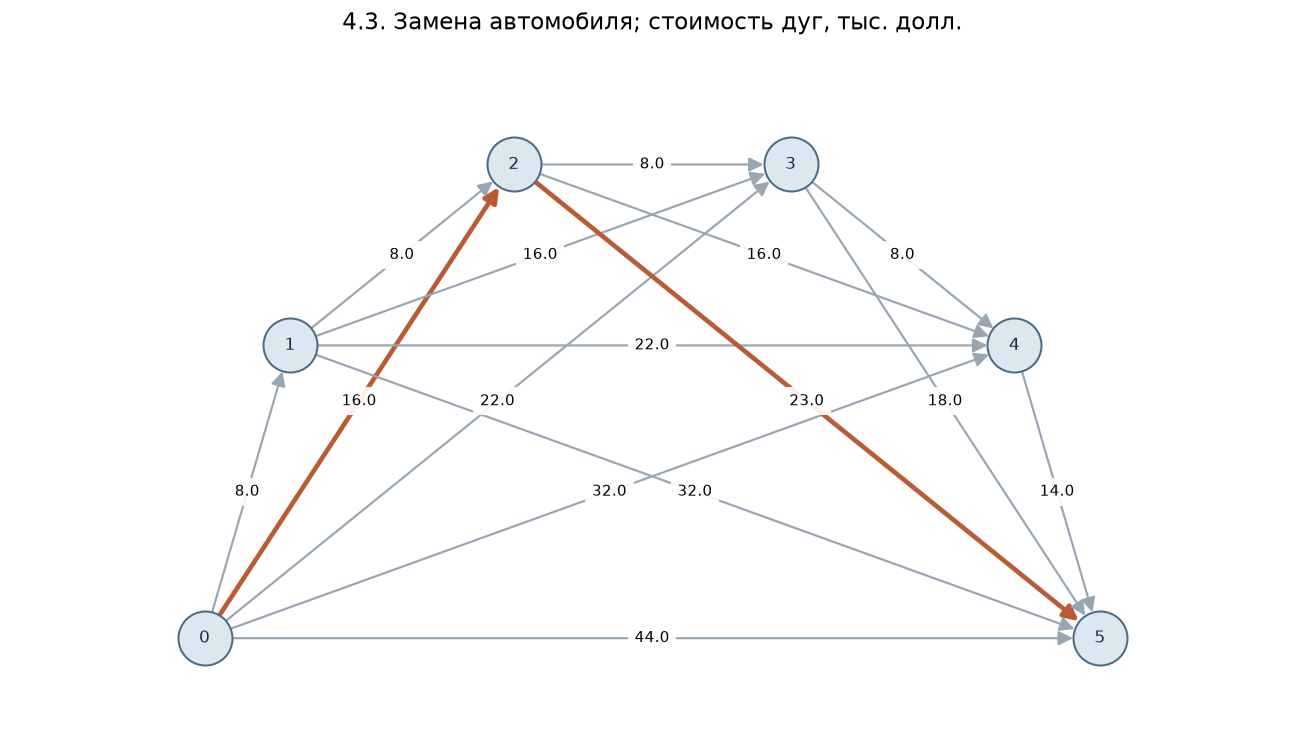

,Все оптимальные графики,"Стоимость, долл."
0,0 → 1 → 2 → 5,39000
1,0 → 2 → 5,39000


In [6]:
purchase_price_43 = 12000
maintenance_43 = [2000, 4000, 5000, 9000, 12000]
trade_in_43 = {0: 7000, 1: 6000, 2: 2000, 3: 1000, 4: 0}
car_graph_43 = nx.DiGraph()
car_graph_43.add_nodes_from(range(6))
for start in range(5):
    for end in range(start + 1, 6):
        age = end - start
        upkeep = sum(maintenance_43[:age])
        resale = trade_in_43[age] if end < 5 else 0
        car_graph_43.add_edge(start, end, weight=purchase_price_43 + upkeep - resale,
                             purchase=purchase_price_43, maintenance=upkeep, trade_in=resale)

def dag_shortest_path_43(graph, source, target):
    distance = {node: float("inf") for node in graph.nodes}
    predecessor = {}
    distance[source] = 0
    for node in nx.topological_sort(graph):
        for successor, data in graph[node].items():
            candidate = distance[node] + data["weight"]
            if candidate < distance[successor]:
                distance[successor] = candidate
                predecessor[successor] = node
    path = [target]
    while path[-1] != source:
        path.append(predecessor[path[-1]])
    return distance[target], path[::-1], distance

car_cost_43, car_path_43, car_distances_43 = dag_shortest_path_43(car_graph_43, 0, 5)
display(pd.DataFrame([
    {"Покупка в году": i, "Использовать до года": j, "Срок, лет": j - i, "Стоимость дуги, долл.": data["weight"]}
    for i, j, data in car_graph_43.edges(data=True)
]))
car_cost_table_43 = pd.DataFrame([
    {"Период": f"{i}–{j}", "Покупка, долл.": car_graph_43[i][j]["purchase"],
     "Содержание, долл.": car_graph_43[i][j]["maintenance"],
     "Трейд-ин, долл.": car_graph_43[i][j]["trade_in"],
     "Чистые затраты, долл.": car_graph_43[i][j]["weight"]}
    for i, j in zip(car_path_43, car_path_43[1:])
])
display(car_cost_table_43)
display(pd.DataFrame({"Момент": list(car_distances_43), "Минимальные расходы до момента, долл.": list(car_distances_43.values())}))
car_positions_43 = {i: (np.cos(np.pi - i * np.pi / 5), np.sin(np.pi - i * np.pi / 5)) for i in range(6)}
draw_graph(car_graph_43, pos=car_positions_43,
           edge_labels={(i, j): data["weight"] / 1000 for i, j, data in car_graph_43.edges(data=True)},
           highlight_edges=list(zip(car_path_43, car_path_43[1:])),
           title="4.3. Замена автомобиля; стоимость дуг, тыс. долл.")
all_car_paths_43 = list(nx.all_simple_paths(car_graph_43, 0, 5))
optimal_car_paths_43 = [path for path in all_car_paths_43
                        if nx.path_weight(car_graph_43, path, "weight") == car_cost_43]
display(pd.DataFrame({"Все оптимальные графики": [" → ".join(map(str, path)) for path in optimal_car_paths_43],
                      "Стоимость, долл.": car_cost_43}))
assert car_cost_43 == 39000
assert car_cost_table_43["Чистые затраты, долл."].sum() == car_cost_43
assert set(map(tuple, optimal_car_paths_43)) == {(0, 2, 5), (0, 1, 2, 5)}

Проверим альтернативное граничное условие — продажу в конце пятого года. Для графиков с хотя бы одной заменой все необходимые цены продажи известны. График без замен имеет стоимость $44\,000-r_5$, где отсутствующее в PDF значение $r_5$ остаётся параметром, а не заменяется вымышленным числом.

In [7]:
terminal_sale_rows_43 = []
for path in all_car_paths_43:
    final_age = path[-1] - path[-2]
    if final_age in trade_in_43:
        terminal_sale_rows_43.append({
            "График": " → ".join(map(str, path)),
            "Стоимость с продажей в конце, долл.": nx.path_weight(car_graph_43, path, "weight") - trade_in_43[final_age]
        })
terminal_sale_table_43 = pd.DataFrame(terminal_sale_rows_43)
best_known_sale_cost_43 = terminal_sale_table_43["Стоимость с продажей в конце, долл."].min()
display(terminal_sale_table_43.loc[
    terminal_sale_table_43["Стоимость с продажей в конце, долл."] == best_known_sale_cost_43
].reset_index(drop=True))
assert best_known_sale_cost_43 == 38000

,График,"Стоимость с продажей в конце, долл."
0,0 → 1 → 2 → 5,38000
1,0 → 1 → 4 → 5,38000
2,0 → 2 → 5,38000
3,0 → 3 → 4 → 5,38000
4,0 → 3 → 5,38000


### Ответ

1. При сохранении автомобиля в конце горизонта минимальные расходы равны **39 000 долл.** Оптимальный график с одной заменой: **$0\to2\to5$**, то есть заменить автомобиль через два года, затем использовать новый ещё три года.
2. Разложение стоимости: две покупки — $24\,000$; содержание — $(2\,000+4\,000)+(2\,000+4\,000+5\,000)=17\,000$; трейд-ин двухлетнего автомобиля — $2\,000$. Итого $24\,000+17\,000-2\,000=39\,000$ долл. Дополнительные расходы после уже состоявшейся первоначальной покупки составляют $27\,000$ долл.
3. Другой оптимальный график — $0\to1\to2\to5$ — имеет ту же стоимость. График $0\to2\to5$ удобнее тем, что требует одной замены.
4. Если дополнительно обязать продать автомобиль в момент $5$, оптимум равен $\min(38\,000,44\,000-r_5)$ долл. При $r_5\le6\,000$ он равен **38 000 долл.**, но без цены $r_5$ и правила о конечной продаже этот альтернативный ответ нельзя выдавать за безусловно заданный PDF.

## Задача 4.4

### Условие

Рассмотрим группу из $n_S$ студентов, которых нужно сопоставить с $n_P$ исследовательскими проектами. У каждого студента есть предпочтения относительно проектов, над которыми он хочет работать, обозначенные числом $w_{sp}\in\{1,\ldots,5\}$, где чем выше число, тем выше предпочтение студента $s$ проекту $p$. В то же время каждый проект имеет ограниченное количество доступных мест $c_p$ для студентов. Ваша цель — максимизировать удовлетворенность как студентов, так и руководителей проектов, сопоставляя студентов с предпочитаемыми ими проектами при соблюдении ограничений по вместимости проектов. Объясните, как создать модель сетевой оптимизации для решения задачи максимизации удовлетворенности студентов при соблюдении ограничений по вместимости проектов.

### Дано

Конкретные числа в условии отсутствуют. Для демонстрации выбраны шесть студентов и три проекта: A — анализ данных, B — оптимизация расписаний, C — моделирование транспорта. Данные заданы явно, поэтому пример воспроизводится без случайной генерации.

| Студент | A | B | C |
|:--|--:|--:|--:|
| S1 | 5 | 2 | 1 |
| S2 | 5 | 4 | 2 |
| S3 | 5 | 3 | 4 |
| S4 | 1 | 5 | 3 |
| S5 | 2 | 5 | 4 |
| S6 | 2 | 3 | 5 |
| Вместимость | 2 | 2 | 2 |

Для каждого студента требуется ровно один проект. Суммарная вместимость равна числу студентов. Отдельных оценок руководителей в условии нет: их требования представлены вместимостью, а целевая функция использует только заданные $w_{sp}$.

### Математическая модель

Пусть $x_{sp}=1$, если студент $s$ назначен на проект $p$:

$$\max \sum_{s\in S}\sum_{p\in P}w_{sp}x_{sp},\qquad
\sum_{p\in P}x_{sp}=1\ (s\in S),\qquad
\sum_{s\in S}x_{sp}\le c_p\ (p\in P),\qquad x_{sp}\in\{0,1\}.$$

Сеть имеет слои «источник — студенты — проекты — сток». Дуги от источника имеют пропускную способность 1 и стоимость 0; дуга $(s,p)$ — способность 1 и стоимость $-w_{sp}$; дуга от проекта к стоку — способность $c_p$ и стоимость 0. Требуется поток величины $|S|$ минимальной стоимости. При недостатке мест сначала следует проверить выполнимость: поток меньшей величины не является полным распределением.

Матрица балансов ориентированной сети полностью унимодулярна. При целочисленных потребностях и пропускных способностях существует целочисленное оптимальное решение линейной релаксации; отдельный MILO-решатель не требуется.

### Найти

1. Полное распределение студентов по проектам с максимальной суммой предпочтений.
2. Загрузку проектов и значение целевой функции.

### Решение

На первом рисунке показаны все допустимые назначения; стоимости внутренних дуг равны оценкам из таблицы «Дано» с обратным знаком. Второй рисунок показывает только дуги с единичным потоком и все их численные параметры.

,Студент,Проект,Оценка
0,S1,A,5
1,S2,A,5
2,S3,C,4
3,S4,B,5
4,S5,B,5
5,S6,C,5


,Проект,Вместимость,Назначено
0,A,2,2
1,B,2,2
2,C,2,2


,Показатель,Значение
0,Распределено студентов,6
1,Сумма предпочтений,29


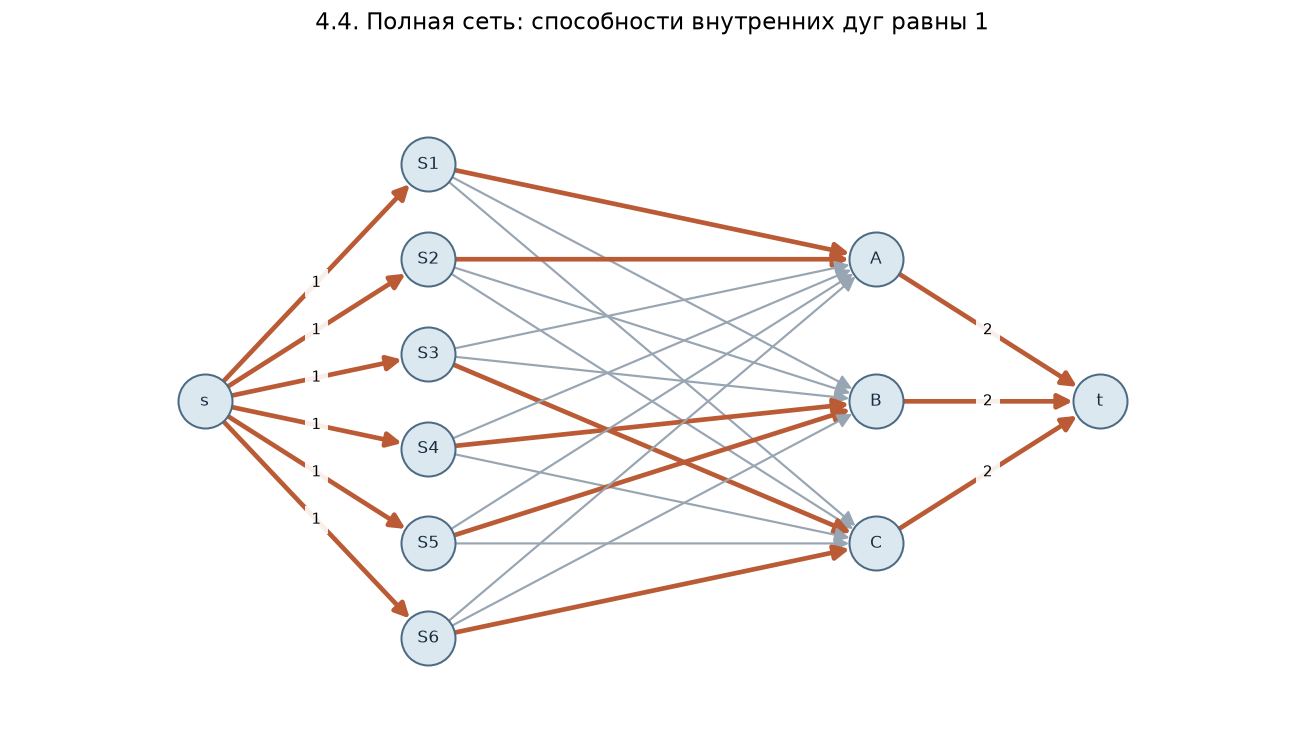

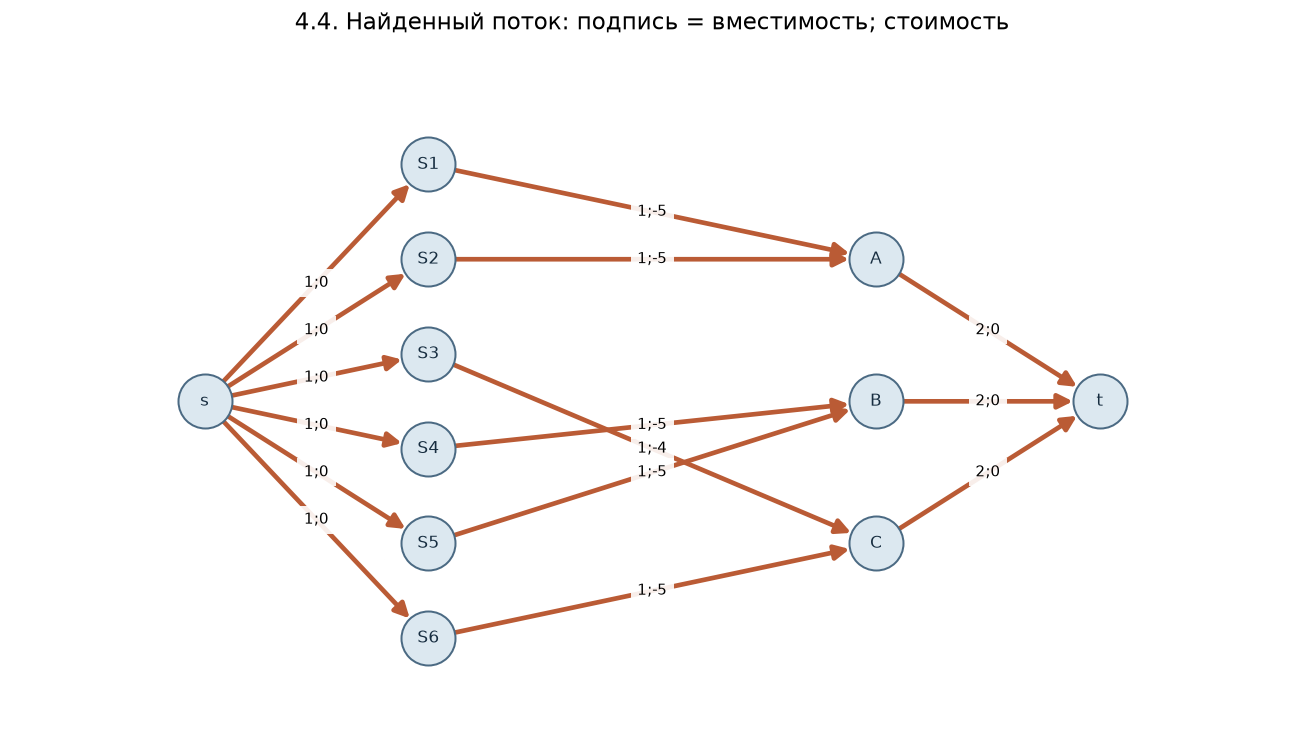

In [8]:
students4 = [f"S{i}" for i in range(1, 7)]
projects4 = ["A", "B", "C"]
preferences4 = pd.DataFrame(
    [[5, 2, 1], [5, 4, 2], [5, 3, 4], [1, 5, 3], [2, 5, 4], [2, 3, 5]],
    index=students4, columns=projects4
)
capacities4 = {project: 2 for project in projects4}
network4 = nx.DiGraph()
network4.add_node("s", demand=-len(students4))
network4.add_node("t", demand=len(students4))
for student in students4:
    network4.add_edge("s", student, capacity=1, weight=0)
    for project in projects4:
        network4.add_edge(student, project, capacity=1, weight=-int(preferences4.loc[student, project]))
for project in projects4:
    network4.add_edge(project, "t", capacity=capacities4[project], weight=0)
cost4, flow4 = nx.network_simplex(network4)
assignment4 = pd.DataFrame([
    {"Студент": student, "Проект": project, "Оценка": int(preferences4.loc[student, project])}
    for student in students4 for project in projects4 if flow4[student][project] == 1
])
occupancy4 = pd.DataFrame([
    {"Проект": project, "Вместимость": capacities4[project], "Назначено": flow4[project]["t"]}
    for project in projects4
])
assert assignment4["Студент"].nunique() == len(students4)
assert (occupancy4["Назначено"] <= occupancy4["Вместимость"]).all()
assert assignment4["Оценка"].sum() == -cost4 == 29
display(assignment4, occupancy4)
display(pd.DataFrame({"Показатель": ["Распределено студентов", "Сумма предпочтений"], "Значение": [len(assignment4), -cost4]}))
positions4 = {"s": (-1, 2.5), "t": (3, 2.5)}
positions4.update({student: (0, 5 - i) for i, student in enumerate(students4)})
positions4.update({project: (2, 4 - 1.5 * i) for i, project in enumerate(projects4)})
selected4 = [(u, v) for u, v in network4.edges if flow4[u][v] > 0]
boundary_labels4 = {(u, v): data["capacity"] for u, v, data in network4.edges(data=True) if u == "s" or v == "t"}
draw_graph(network4, pos=positions4, edge_labels=boundary_labels4, highlight_edges=selected4,
           title="4.4. Полная сеть: способности внутренних дуг равны 1")
active4 = network4.edge_subgraph(selected4).copy()
labels4 = {(u, v): f"{data['capacity']};{data['weight']}" for u, v, data in active4.edges(data=True)}
draw_graph(active4, pos=positions4, edge_labels=labels4, highlight_edges=selected4,
           title="4.4. Найденный поток: подпись = вместимость; стоимость")

### Ответ

1. Оптимальное распределение: **A — S1, S2; B — S4, S5; C — S3, S6**. Все шесть студентов получили проект, вместимость каждого проекта соблюдена.
2. Суммарная оценка равна **29**, стоимость потока равна **−29**. Оценка 30 недостижима: три студента S1, S2 и S3 предпочитают A с оценкой 5, а мест только два. Следовательно, верхняя граница равна 29, и найденное решение ее достигает.

## Задача 4.5

### Условие

Рассмотрим организацию светского мероприятия, на котором участников нужно разбить на пары для участия в активностях. Каждый участник может указать список людей, с которыми он хотел бы быть в паре. Предполагая, что количество участников четное, сформулируйте задачу максимизации количества желаемых пар.

### Дано

Численные данные выбраны для демонстрации. Участников восемь; желаемой считаем пару с **взаимным** предпочтением. Это уточнение необходимо: условие не задает правило для односторонних предпочтений.

| Участник | Желаемые партнеры | Группа учебного примера |
|:--|:--|:--|
| A | E, F | L |
| B | E | L |
| C | F, G | L |
| D | G | L |
| E | A, B | R |
| F | A, C | R |
| G | C, D | R |
| H | Нет предпочтений | R |

Граф желаемых пар в этом примере двудольный: $L=\{A,B,C,D\}$, $R=\{E,F,G,H\}$. В исходном условии разделения участников на две группы **нет**; оно не предполагается для общей модели ниже.

### Математическая модель

Для произвольного четного множества участников $V$ обозначим через $q_{ij}\in\{0,1\}$ признак желаемой пары. Переменная $x_{ij}$ определена для каждой неупорядоченной пары различных участников, включая нежелательные:

$$\max\sum_{\{i,j\}\subset V}q_{ij}x_{ij},\qquad
\sum_{j\ne i}x_{\{i,j\}}=1\quad(i\in V),\qquad x_{ij}\in\{0,1\}.$$

Это совершенное паросочетание максимального веса. Равенства обеспечивают участие каждого человека ровно в одной паре. Если вместо этого найти максимальное паросочетание только на желаемых ребрах, оставшихся участников можно попарно объединить произвольно: между двумя оставшимися участниками желаемого ребра уже нет, иначе паросочетание не было бы максимальным.

**Сведение к максимальному потоку для двудольного графа.** Добавим источник $s$, сток $t$, дуги $s\to L$, желаемые дуги $L\to R$ и дуги $R\to t$; все пропускные способности равны 1. Целочисленный максимальный поток задает максимум желаемых пар. Остаток дополняется до полного разбиения.

Для общего недвудольного графа такое прямое сведение некорректно: например, в треугольнике релаксация ограничений степеней допускает по $1/2$ на каждом ребре. Требуется алгоритм общего паросочетания, например алгоритм Эдмондса, или указанная бинарная модель. Полная унимодулярность потоковой постановки относится к двудольному случаю.

### Найти

1. Максимальное число желаемых пар.
2. Полное разбиение восьми участников на четыре пары.

### Решение

,Участник 1,Участник 2,Желаемая пара
0,A,E,1
1,C,F,1
2,D,G,1
3,B,H,0


,Показатель,Значение
0,Желаемых пар,3
1,Всего пар,4
2,Нежелаемых пар,1


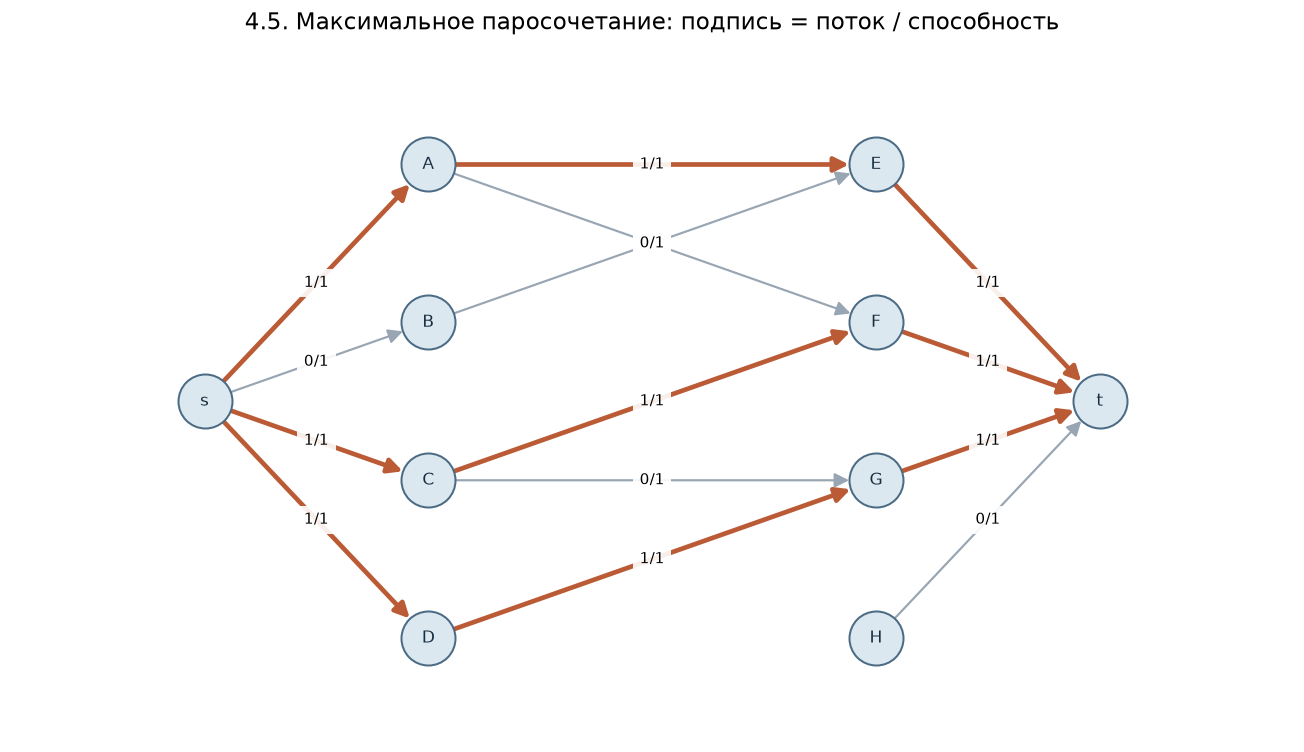

In [9]:
left5 = ["A", "B", "C", "D"]
right5 = ["E", "F", "G", "H"]
desired5 = [("A", "E"), ("A", "F"), ("B", "E"), ("C", "F"), ("C", "G"), ("D", "G")]
network5 = nx.DiGraph()
network5.add_edges_from([("s", person) for person in left5], capacity=1)
network5.add_edges_from(desired5, capacity=1)
network5.add_edges_from([(person, "t") for person in right5], capacity=1)
value5, flow5 = nx.maximum_flow(network5, "s", "t", flow_func=nx.algorithms.flow.edmonds_karp)
desired_pairs5 = [(u, v) for u, v in desired5 if flow5[u][v] == 1]
used5 = {person for pair in desired_pairs5 for person in pair}
remaining5 = sorted(set(left5 + right5) - used5)
additional5 = list(zip(remaining5[::2], remaining5[1::2]))
pairs5 = desired_pairs5 + additional5
result5 = pd.DataFrame([
    {"Участник 1": u, "Участник 2": v, "Желаемая пара": int((u, v) in desired5 or (v, u) in desired5)}
    for u, v in pairs5
])
general5 = nx.Graph()
general5.add_nodes_from(left5 + right5)
for u, v in itertools.combinations(left5 + right5, 2):
    general5.add_edge(u, v, weight=int((u, v) in desired5 or (v, u) in desired5))
matching5 = nx.max_weight_matching(general5, maxcardinality=True, weight="weight")
assert len(pairs5) == len(matching5) == 4
assert len({person for pair in pairs5 for person in pair}) == 8
assert value5 == result5["Желаемая пара"].sum() == 3
assert sum(general5[u][v]["weight"] for u, v in matching5) == value5
display(result5)
display(pd.DataFrame({"Показатель": ["Желаемых пар", "Всего пар", "Нежелаемых пар"], "Значение": [value5, len(pairs5), len(additional5)]}))
positions5 = {"s": (-1, 1.5), "t": (3, 1.5)}
positions5.update({person: (0, 3 - i) for i, person in enumerate(left5)})
positions5.update({person: (2, 3 - i) for i, person in enumerate(right5)})
labels5 = {(u, v): f"{flow5[u][v]}/{data['capacity']}" for u, v, data in network5.edges(data=True)}
selected5 = [(u, v) for u, v in network5.edges if flow5[u][v] > 0]
draw_graph(network5, pos=positions5, edge_labels=labels5, highlight_edges=selected5,
           title="4.5. Максимальное паросочетание: подпись = поток / способность")

### Ответ

1. Максимум — **3 желаемые пары**. Больше быть не может: все желаемые ребра приходят только в три вершины E, F и G. Поток величины 3 достигает этой верхней границы.
2. Полное разбиение содержит **4 пары**, из которых одна нежелаемая. Один оптимальный вариант: **A–F, B–E, C–G, D–H**; конкретное разбиение, найденное алгоритмом, приведено в таблице. Алгоритм общего взвешенного паросочетания независимо подтверждает значение 3.

## Задача 4.6

### Условие

Представьте, что вы куратор престижной художественной выставки, и у вас есть обширная коллекция произведений искусства от разных художников, каждое из которых имеет свой уникальный стиль и определенный набор используемых цветов. Задача состоит в том, чтобы расположить эти произведения искусства так, чтобы максимизировать визуальную привлекательность выставки. Чтобы создать визуально ошеломляющие впечатления, вы решаете повесить произведения искусства на стены большой галереи. Загвоздка в том, что вы хотите организовать их так, чтобы два соседних произведения искусства не использовали одни и те же цвета. Кроме того, художники предоставили вам список ограничений, указывающих, какие произведения искусства не следует размещать рядом друг с другом из-за тематических или стилистических конфликтов. Сформулируйте задачу поиска наиболее эстетически приятного расположения произведений искусства на стенах с учетом предоставленных ограничений.

### Дано

В методичке отсутствуют конкретная коллекция, геометрия стен и численная оценка эстетики. Для демонстрации выбрана следующая коллекция.

| Картина | Используемые краски | Дополнительные конфликты |
|:--|:--|:--|
| P1 | красная, золотая | P5 |
| P2 | синяя, золотая | P6 |
| P3 | зеленая, золотая | P7 |
| P4 | красная, белая | P7 |
| P5 | синяя, черная | P1 |
| P6 | зеленая, белая | P2 |
| P7 | фиолетовая, черная | P3, P4 |

Для модели раскраски принимается дополнительное правило: **внутри одной стены-группы каждая пара картин должна быть совместима**; разные стены разделены. Вместимость стены не ограничена. Это достаточное, более строгое требование, чем запрет только непосредственного физического соседства. Оно позволяет безопасно расположить картины внутри каждой группы в любом порядке.

### Математическая модель

Построим граф конфликтов $G=(V,E)$: вершина соответствует картине, а ребро — общей краске либо тематическому или стилистическому запрету. Цвет вершины означает номер стены, а не краску на картине. По аналогии с примером 4.7 главы выбираем измеримую цель: использовать минимальное число совместимых групп.

Пусть $K=|V|$, $x_{ik}=1$, если картина $i$ отнесена к группе $k$, и $y_k=1$, если группа используется:

$$\min\sum_{k=1}^{K}y_k,$$
$$\sum_{k=1}^{K}x_{ik}=1\quad(i\in V),\qquad
x_{ik}\le y_k\quad(i\in V,\ k=1,\ldots,K),$$
$$x_{ik}+x_{jk}\le1\quad(\{i,j\}\in E,\ k=1,\ldots,K),\qquad x_{ik},y_k\in\{0,1\}.$$

Ограничения $y_k\ge y_{k+1}$ устраняют часть симметрии нумерации групп. Это MILO-модель раскраски; целочисленность здесь существенна, потоковая гарантия полной унимодулярности отсутствует.

Если под соседством понимать только соседние позиции на стене, нужно дополнительно задавать места, отношения соседства и переменные размещения по местам. Без этих данных и функции эстетической оценки исходный текст не определяет единственной численной задачи «максимизации красоты». Представленная раскраска решает явно сформулированную задачу совместимого группирования.

### Найти

1. Минимальное число групп при принятом правиле совместимости.
2. Допустимое распределение картин, не нарушающее цветовые и тематические запреты.

### Решение

,Картина 1,Картина 2,Причина
0,P1,P2,золотая
1,P1,P3,золотая
2,P1,P4,красная
3,P1,P5,тематика / стиль
4,P2,P3,золотая
5,P2,P5,синяя
6,P2,P6,тематика / стиль
7,P3,P6,зеленая
8,P3,P7,тематика / стиль
9,P4,P6,белая


,Картина,Группа
0,P1,2
1,P2,3
2,P3,1
3,P4,1
4,P5,1
5,P6,2
6,P7,2


,Показатель,Значение
0,Число конфликтов,12
1,Минимум групп,3
2,Размер наибольшей клики,3


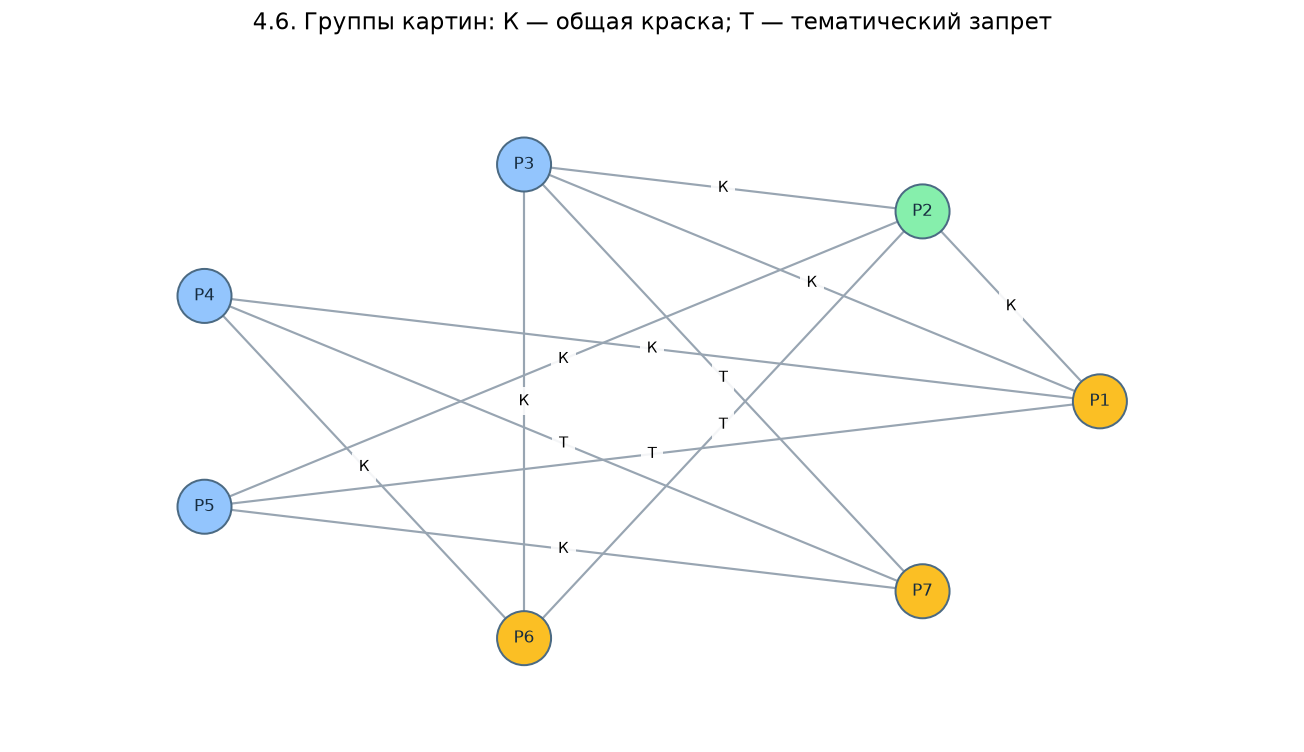

In [10]:
pigments6 = {
    "P1": {"красная", "золотая"}, "P2": {"синяя", "золотая"},
    "P3": {"зеленая", "золотая"}, "P4": {"красная", "белая"},
    "P5": {"синяя", "черная"}, "P6": {"зеленая", "белая"},
    "P7": {"фиолетовая", "черная"}
}
thematic6 = {frozenset(pair) for pair in [("P1", "P5"), ("P2", "P6"), ("P3", "P7"), ("P4", "P7")]}
conflict6 = nx.Graph()
conflict6.add_nodes_from(pigments6)
conflict_rows6 = []
for first, second in itertools.combinations(pigments6, 2):
    common = pigments6[first] & pigments6[second]
    thematic = frozenset((first, second)) in thematic6
    if common or thematic:
        reason = ", ".join(sorted(common)) if common else "тематика / стиль"
        conflict6.add_edge(first, second, reason=reason)
        conflict_rows6.append({"Картина 1": first, "Картина 2": second, "Причина": reason})
coloring6 = pyo.ConcreteModel()
coloring6.pictures = pyo.Set(initialize=list(pigments6))
coloring6.groups = pyo.RangeSet(1, len(pigments6))
coloring6.edges = pyo.Set(initialize=list(conflict6.edges), dimen=2)
coloring6.x = pyo.Var(coloring6.pictures, coloring6.groups, domain=pyo.Binary)
coloring6.y = pyo.Var(coloring6.groups, domain=pyo.Binary)
coloring6.assign = pyo.Constraint(coloring6.pictures, rule=lambda m, i: sum(m.x[i, k] for k in m.groups) == 1)
coloring6.use = pyo.Constraint(coloring6.pictures, coloring6.groups, rule=lambda m, i, k: m.x[i, k] <= m.y[k])
coloring6.conflicts = pyo.Constraint(coloring6.edges, coloring6.groups, rule=lambda m, i, j, k: m.x[i, k] + m.x[j, k] <= 1)
coloring6.symmetry = pyo.Constraint(range(1, len(pigments6)), rule=lambda m, k: m.y[k] >= m.y[k + 1])
coloring6.objective = pyo.Objective(expr=sum(coloring6.y[k] for k in coloring6.groups), sense=pyo.minimize)
solve_model(coloring6)
groups6 = {picture: next(k for k in coloring6.groups if pyo.value(coloring6.x[picture, k]) > 0.5) for picture in pigments6}
number6 = int(round(pyo.value(coloring6.objective)))
clique6 = max(nx.find_cliques(conflict6), key=len)
assert all(groups6[u] != groups6[v] for u, v in conflict6.edges)
assert number6 == len(set(groups6.values())) == len(clique6) == 3
display(pd.DataFrame(conflict_rows6))
display(pd.DataFrame([{"Картина": picture, "Группа": group} for picture, group in groups6.items()]))
display(pd.DataFrame({"Показатель": ["Число конфликтов", "Минимум групп", "Размер наибольшей клики"], "Значение": [conflict6.number_of_edges(), number6, len(clique6)]}))
palette6 = ["#93c5fd", "#fbbf24", "#86efac", "#c4b5fd", "#fca5a5", "#67e8f9", "#d1d5db"]
labels6 = {(u, v): "К" if pigments6[u] & pigments6[v] else "Т" for u, v in conflict6.edges}
draw_graph(conflict6, pos=nx.circular_layout(conflict6), edge_labels=labels6,
           node_colors=[palette6[groups6[node] - 1] for node in conflict6.nodes],
           title="4.6. Группы картин: К — общая краска; Т — тематический запрет")

### Ответ

1. При принятом правиле требуется **3 группы**. Картины P1, P2 и P3 образуют треугольник конфликтов из-за общей золотой краски, поэтому двух групп недостаточно. Найденная раскраска тремя цветами доказывает оптимальность.
2. Один допустимый вариант: **{P1, P6, P7}, {P2, P4}, {P3, P5}**. Распределение решателя приведено в таблице; оно может отличаться нумерацией и составом групп при той же оптимальной цели. В каждой группе нет ни общих красок, ни указанных тематических конфликтов.

## Задача 4.7

### Условие

В городе Техвилль группа инженеров и специалистов по данным сталкивается с уникальной и сложной задачей. Им поручено создать эффективную кабельную сеть, используя $n$ стратегически расположенных разъемов. Предположим, что стоимость прокладки прямого кабеля между двумя разъемами $i$ и $j$ задается как $w_{ij}\geq0$. Сформулируйте математическую модель для определения самой дешевой возможной сети при условии, что можно перемещаться между любыми двумя разъемами по кабелям (возможно, через другие разъемы). Как бы вы эффективно решили эту задачу?

### Дано

Числовые данные выбраны для демонстрации: шесть разъемов и симметричная матрица стоимости прямых соединений, тыс. руб. Все соединения доступны. Значения зафиксированы, поэтому пример воспроизводится без генератора случайных чисел.

| Разъем | A | B | C | D | E | F |
|:--|--:|--:|--:|--:|--:|--:|
| A | 0 | 4 | 4 | 4 | 4 | 8 |
| B | 4 | 0 | 7 | 8 | 7 | 11 |
| C | 4 | 7 | 0 | 7 | 8 | 4 |
| D | 4 | 8 | 7 | 0 | 7 | 5 |
| E | 4 | 7 | 8 | 7 | 0 | 10 |
| F | 8 | 11 | 4 | 5 | 10 | 0 |

### Математическая модель

Пусть $G=(V,E)$ — полный неориентированный граф; $x_e\in\{0,1\}$ показывает, прокладывается ли кабель $e$. Обозначим через $\delta(S)$ ребра с одним концом в $S$, а другим вне $S$. Тогда

$$\min\sum_{e\in E}w_e x_e,$$
$$\sum_{e\in\delta(S)}x_e\geq1
\quad\forall\,\varnothing\ne S\subsetneq V.$$

Ограничения разрезов обеспечивают связность. Из любого цикла можно удалить ребро, сохранив связность и не увеличив стоимость, поскольку $w_e\geq0$. Следовательно, существует оптимальное решение в виде минимального остовного дерева. Для него достаточно $|V|-1$ ребер. Эффективный метод — алгоритм Краскала: сортировать ребра по стоимости и добавлять ребро, если оно не создает цикл. Основная трудоемкость составляет $O(|E|\log|E|)$.

### Найти

1. Набор кабелей минимальной суммарной стоимости.
2. Общую стоимость и подтверждение связности сети.

### Решение

,A,B,C,D,E,F
"Стоимость, тыс. руб.",,,,,,
A,0,4,4,4,4,8
B,4,0,7,8,7,11
C,4,7,0,7,8,4
D,4,8,7,0,7,5
E,4,7,8,7,0,10
F,8,11,4,5,10,0


,Кабель,"Стоимость, тыс. руб."
0,A—B,4
1,A—C,4
2,A—D,4
3,A—E,4
4,C—F,4


,"Общая стоимость, тыс. руб.",Количество кабелей,Связность
0,20,5,True


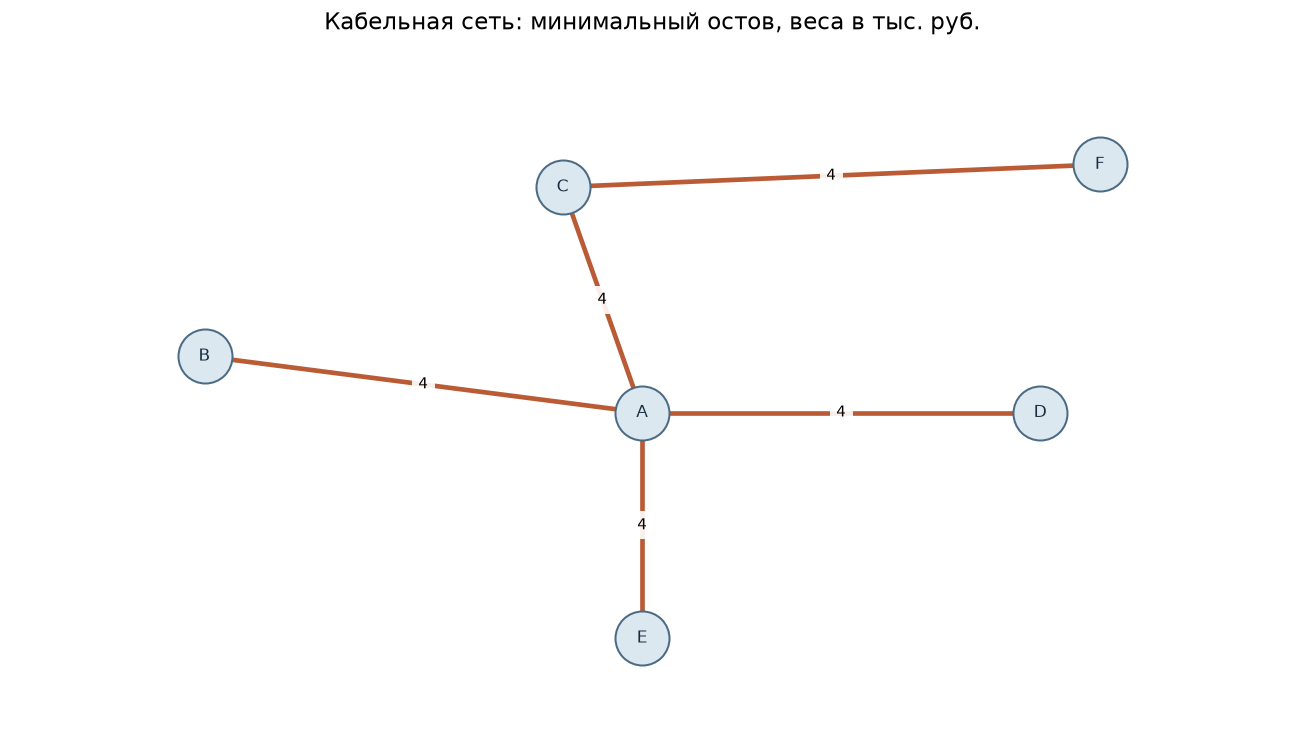

In [11]:
cable_nodes = list("ABCDEF")
cable_costs = np.array([
    [0, 4, 4, 4, 4, 8],
    [4, 0, 7, 8, 7, 11],
    [4, 7, 0, 7, 8, 4],
    [4, 8, 7, 0, 7, 5],
    [4, 7, 8, 7, 0, 10],
    [8, 11, 4, 5, 10, 0],
], dtype=int)
cable_graph = nx.Graph()
cable_graph.add_nodes_from(cable_nodes)
for i, j in itertools.combinations(range(len(cable_nodes)), 2):
    cable_graph.add_edge(cable_nodes[i], cable_nodes[j], weight=int(cable_costs[i, j]))

cable_positions = {
    "A": (0, 0), "B": (-2.2, 0.5), "C": (-0.4, 2),
    "D": (2, 0), "E": (0, -2), "F": (2.3, 2.2)
}
mst = nx.minimum_spanning_tree(cable_graph, algorithm="kruskal", weight="weight")
mst_cost = int(mst.size(weight="weight"))
display(pd.DataFrame(cable_costs, index=cable_nodes, columns=cable_nodes)
        .rename_axis("Стоимость, тыс. руб."))
display(pd.DataFrame([
    {"Кабель": f"{u}—{v}", "Стоимость, тыс. руб.": d["weight"]}
    for u, v, d in mst.edges(data=True)
]))
display(pd.DataFrame([{
    "Общая стоимость, тыс. руб.": mst_cost,
    "Количество кабелей": mst.number_of_edges(),
    "Связность": nx.is_connected(mst),
}]))
assert nx.is_tree(mst)
assert mst.number_of_edges() == len(cable_nodes) - 1
assert mst_cost == 20
draw_graph(mst, pos=cable_positions,
           edge_labels=nx.get_edge_attributes(mst, "weight"),
           highlight_edges=list(mst.edges),
           title="Кабельная сеть: минимальный остов, веса в тыс. руб.")

### Ответ

1. Минимальный остов: **A—B, A—C, A—D, A—E, C—F**.
2. Стоимость — **20 тыс. руб.** Все шесть разъемов связаны пятью кабелями. Разъем A имеет степень 4; это допустимо в задаче 4.7, но нарушает ограничение следующей задачи.

## Задача 4.8

### Условие

Рассмотрим снова задачу из предыдущего упражнения. Муниципалитет Техвилля добавляет «простое» дополнительное ограничение: чтобы иметь последовательное соединение разъемов, каждый разъем может быть подключен не более чем к двум другим. Сформулируйте математическую модель, которая включает это ограничение.

### Дано

Используются те же демонстрационные данные, что и в задаче 4.7. Стоимости указаны в тыс. руб.

| Разъем | A | B | C | D | E | F |
|:--|--:|--:|--:|--:|--:|--:|
| A | 0 | 4 | 4 | 4 | 4 | 8 |
| B | 4 | 0 | 7 | 8 | 7 | 11 |
| C | 4 | 7 | 0 | 7 | 8 | 4 |
| D | 4 | 8 | 7 | 0 | 7 | 5 |
| E | 4 | 7 | 8 | 7 | 0 | 10 |
| F | 8 | 11 | 4 | 5 | 10 | 0 |

Дополнительное ограничение: степень каждой вершины не превосходит 2.

### Математическая модель

Сохраняем бинарные переменные $x_e$ и ограничения связности из предыдущей задачи:

$$\min\sum_{e\in E}w_e x_e,$$
$$\sum_{e\in\delta(S)}x_e\geq1
\quad\forall\,\varnothing\ne S\subsetneq V,$$
$$\sum_{e\in\delta(\{v\})}x_e\leq2\quad\forall v\in V,
\qquad x_e\in\{0,1\}.$$

Связный простой граф с максимальной степенью 2 является путем или циклом. При неотрицательных стоимостях из цикла можно удалить ребро, поэтому оптимум всегда достигается на **гамильтоновом пути**. Это открытый вариант задачи коммивояжера. В условии сказано «не более чем к двум», а замыкание в цикл не требуется.

Для сравнения отдельно решим замкнутую задачу коммивояжера: заменим ограничения степени на равенства $\sum_{e\in\delta(\{v\})}x_e=2$. Вместе с ограничениями связности они исключают отдельные подциклы и задают гамильтонов цикл. Такое требование сильнее исходного.

В учебном примере все разрезы перечисляются явно. Для крупных задач их обычно добавляют по мере обнаружения нарушений. В отличие от задачи об остове, задача о кратчайшем гамильтоновом пути в общем случае NP-трудна.

### Найти

1. Самую дешевую связную сеть со степенями вершин не выше 2.
2. Стоимость гамильтонова цикла при дополнительном требовании замыкания.

### Решение

,Модель,"Стоимость, тыс. руб.",Кабелей,Маршрут
0,Исходное условие: путь,24,5,B → A → C → F → D → E
1,Дополнительно: замкнутый цикл,31,6,C → A → B → E → D → F → C


,Разъем,Степень в пути,Степень в цикле
0,A,2,2
1,B,1,2
2,C,2,2
3,D,2,2
4,E,1,2
5,F,2,2


,Сеть,Кабель,"Стоимость, тыс. руб."
0,Путь,A—B,4
1,Путь,A—C,4
2,Путь,C—F,4
3,Путь,D—E,7
4,Путь,D—F,5
5,Цикл,A—B,4
6,Цикл,A—C,4
7,Цикл,B—E,7
8,Цикл,C—F,4
9,Цикл,D—E,7


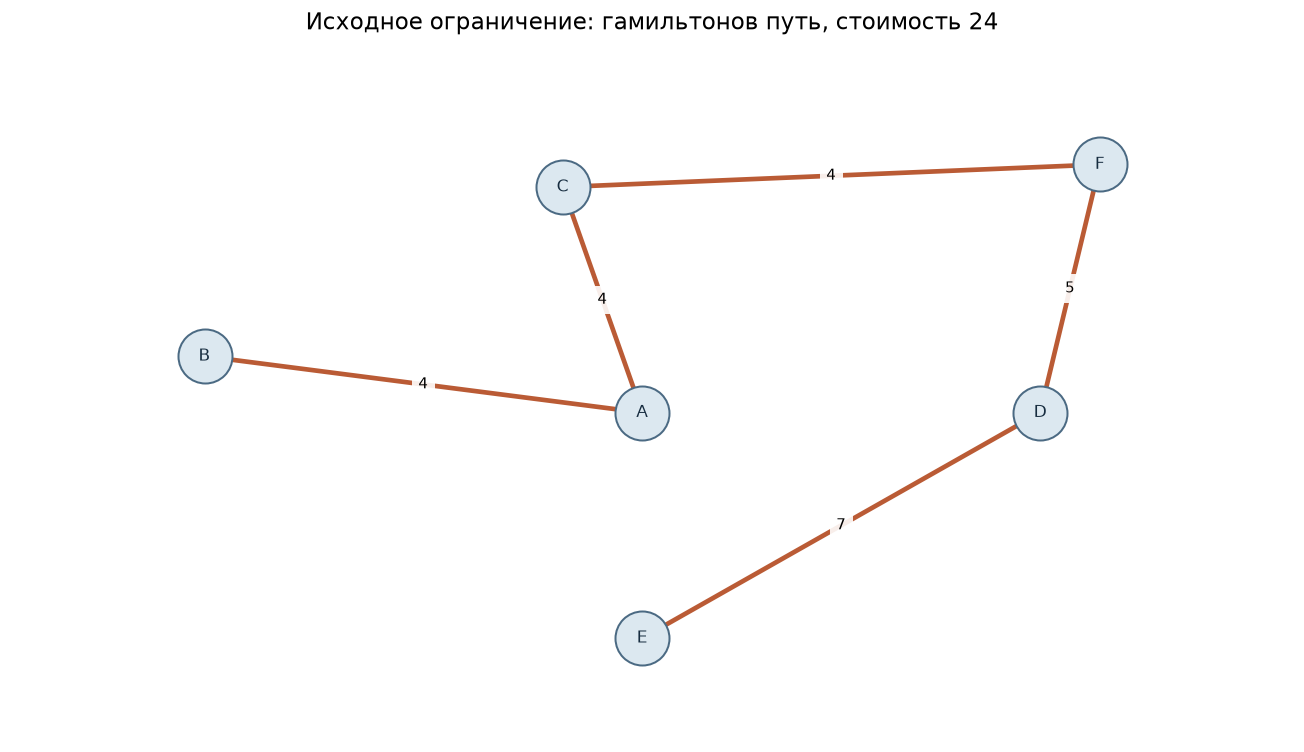

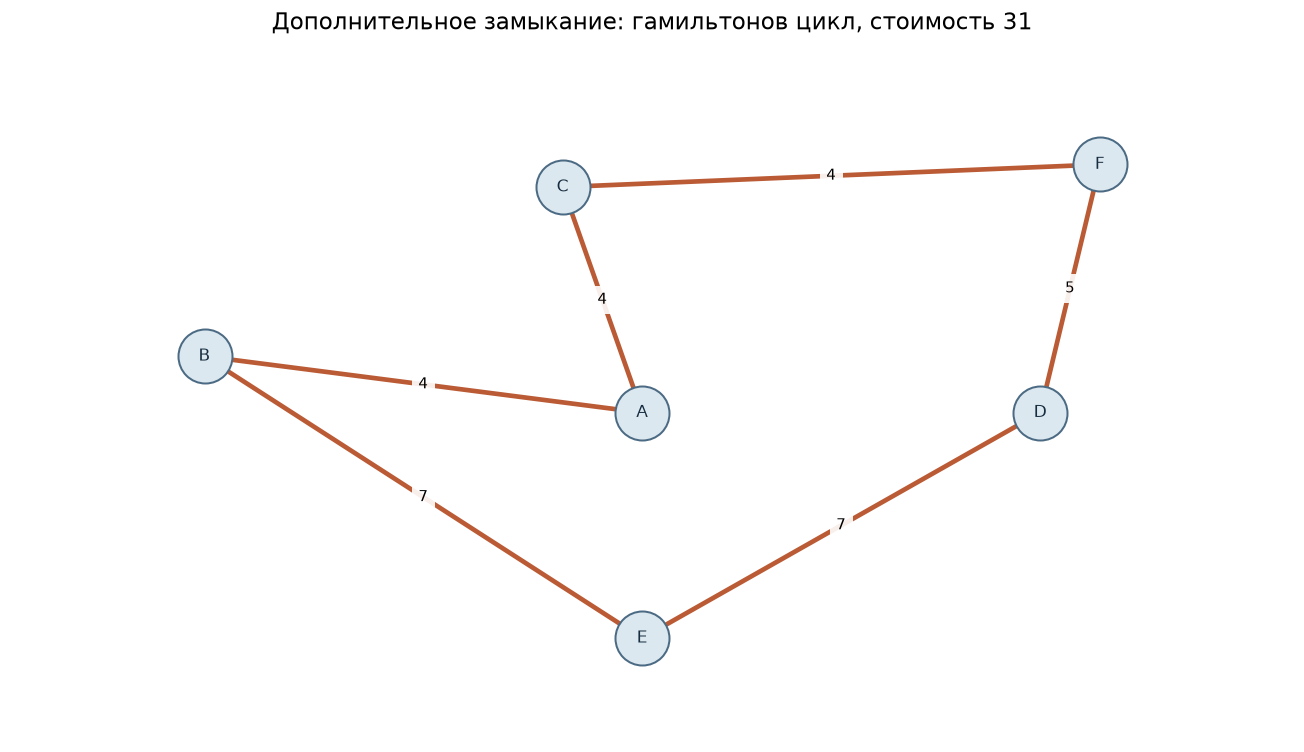

In [12]:
def build_cable_model(require_cycle=False):
    model = pyo.ConcreteModel()
    model.vertices = pyo.Set(initialize=cable_nodes, ordered=True)
    model.edges = pyo.Set(initialize=list(cable_graph.edges), dimen=2)
    model.selected = pyo.Var(model.edges, domain=pyo.Binary)
    model.cost = pyo.Objective(expr=sum(
        cable_graph[u][v]["weight"] * model.selected[u, v]
        for u, v in model.edges
    ), sense=pyo.minimize)
    model.degree = pyo.ConstraintList()
    for node in cable_nodes:
        degree = sum(model.selected[u, v] for u, v in model.edges if node in (u, v))
        model.degree.add(degree == 2 if require_cycle else degree <= 2)
    model.connectivity = pyo.ConstraintList()
    for subset_size in range(1, len(cable_nodes)):
        for subset in itertools.combinations(cable_nodes, subset_size):
            if cable_nodes[0] not in subset:
                continue
            side = set(subset)
            crossing = [(u, v) for u, v in model.edges if (u in side) != (v in side)]
            model.connectivity.add(sum(model.selected[e] for e in crossing) >= 1)
    return model

path_model = build_cable_model()
cycle_model = build_cable_model(require_cycle=True)
solve_model(path_model)
solve_model(cycle_model)

path_edges = [e for e in path_model.edges if pyo.value(path_model.selected[e]) > 0.5]
cycle_edges = [e for e in cycle_model.edges if pyo.value(cycle_model.selected[e]) > 0.5]
path_network = cable_graph.edge_subgraph(path_edges).copy()
cycle_network = cable_graph.edge_subgraph(cycle_edges).copy()
path_cost = int(round(pyo.value(path_model.cost)))
cycle_cost = int(round(pyo.value(cycle_model.cost)))
path_endpoints = sorted(v for v, degree in path_network.degree if degree == 1)
cable_path = nx.shortest_path(path_network, path_endpoints[0], path_endpoints[1])
cable_cycle = nx.cycle_basis(cycle_network)[0]
display(pd.DataFrame([
    {"Модель": "Исходное условие: путь", "Стоимость, тыс. руб.": path_cost,
     "Кабелей": len(path_edges), "Маршрут": " → ".join(cable_path)},
    {"Модель": "Дополнительно: замкнутый цикл", "Стоимость, тыс. руб.": cycle_cost,
     "Кабелей": len(cycle_edges), "Маршрут": " → ".join(cable_cycle + [cable_cycle[0]])},
]))
display(pd.DataFrame([
    {"Разъем": node, "Степень в пути": path_network.degree[node],
     "Степень в цикле": cycle_network.degree[node]}
    for node in cable_nodes
]))
display(pd.DataFrame([
    {"Сеть": name, "Кабель": f"{u}—{v}", "Стоимость, тыс. руб.": cable_graph[u][v]["weight"]}
    for name, edges in [("Путь", path_edges), ("Цикл", cycle_edges)]
    for u, v in edges
]))
assert nx.is_tree(path_network) and set(path_network) == set(cable_nodes)
assert max(dict(path_network.degree).values()) <= 2
assert nx.is_connected(cycle_network) and all(d == 2 for _, d in cycle_network.degree)
assert path_cost == 24 and cycle_cost == 31
assert path_cost >= mst_cost
draw_graph(path_network, pos=cable_positions,
           edge_labels=nx.get_edge_attributes(path_network, "weight"),
           highlight_edges=path_edges,
           title="Исходное ограничение: гамильтонов путь, стоимость 24")
draw_graph(cycle_network, pos=cable_positions,
           edge_labels=nx.get_edge_attributes(cycle_network, "weight"),
           highlight_edges=cycle_edges,
           title="Дополнительное замыкание: гамильтонов цикл, стоимость 31")

### Ответ

1. По исходному условию минимальная стоимость равна **24 тыс. руб.** Один из оптимальных путей: **B—A—C—F—D—E**; его стоимость $4+4+4+5+7=24$. Возможны другие оптимальные пути; найденный решателем вариант приведен в таблице.
2. Если дополнительно потребовать замкнутую сеть, минимальная стоимость равна **31 тыс. руб.** Пример оптимального цикла: **A—B—C—F—D—E—A**, стоимость $4+7+4+5+7+4=31$.
3. Ограничение степени повышает стоимость относительно остова на **4 тыс. руб.** Замыкание пути в оптимальный цикл требует еще **7 тыс. руб.**

## Задача 4.9

### Условие

Рассмотрим ориентированный граф $G=(V,E)$ и две различные вершины $s$ и $t$ в нем. Два пути из $s$ в $t$ называются непересекающимися по ребрам, если каждое ребро графа встречается не более чем в одном из этих путей. Как бы вы определили наибольшее количество непересекающихся по ребрам путей?

### Дано

Топология выбрана для демонстрации. Вершины: $V=\{s,a,b,c,d,e,t\}$, источник — $s$, сток — $t$. Все дуги и их пропускные способности приведены ниже.

| Дуга | Пропускная способность | Дуга | Пропускная способность |
|:--|--:|:--|--:|
| $s\to a$ | 1 | $a\to e$ | 1 |
| $s\to b$ | 1 | $b\to d$ | 1 |
| $s\to c$ | 1 | $b\to e$ | 1 |
| $a\to d$ | 1 | $c\to e$ | 1 |
| $c\to t$ | 1 | $d\to t$ | 1 |
| $e\to t$ | 1 | | |

Единичные пропускные способности следуют из требования непересечения: каждая дуга должна использоваться не более чем одним путем. Произвольные большие емкости решали бы другую задачу.

### Математическая модель

Пусть $f_{uv}$ — поток по дуге $(u,v)$, а $F$ — его величина. Решаем

$$\max F,$$
$$\sum_{(v,u)\in E}f_{vu}-\sum_{(u,v)\in E}f_{uv}
=\begin{cases}F,&v=s,\\-F,&v=t,\\0,&v\notin\{s,t\},\end{cases}
\qquad 0\leq f_{uv}\leq1.$$

Здесь в первом суммировании $v$ — начало дуги, во втором — конец. Матрица балансов является матрицей инцидентности ориентированного графа и полностью унимодулярна. При целых емкостях существует целочисленный оптимальный поток. Он раскладывается на $F$ единичных путей и, возможно, циклы; циклы можно удалить. Емкость 1 исключает совместное использование одной дуги. Общие промежуточные **вершины** допускаются.

Используется алгоритм Эдмондса—Карпа — вариант алгоритма Форда—Фалкерсона, выбирающий увеличивающий путь поиском в ширину. Минимальный разрез дает независимую верхнюю оценку числа путей.

### Найти

1. Максимальное число непересекающихся по ребрам путей из $s$ в $t$.
2. Сами пути и минимальный разрез, подтверждающий оптимальность.

### Решение

,Дуга,Емкость,Поток,В минимальном разрезе
0,s → a,1,1,False
1,s → b,1,1,False
2,s → c,1,1,False
3,a → d,1,1,False
4,a → e,1,0,False
5,b → d,1,0,False
6,b → e,1,1,False
7,c → e,1,0,False
8,c → t,1,1,True
9,d → t,1,1,True


,Номер пути,Путь,Число дуг
0,1,s → c → t,2
1,2,s → a → d → t,3
2,3,s → b → e → t,3


,Максимальный поток,Емкость минимального разреза,Сторона источника,Дуги разреза
0,3,3,"a, b, c, d, e, s",c → t; d → t; e → t


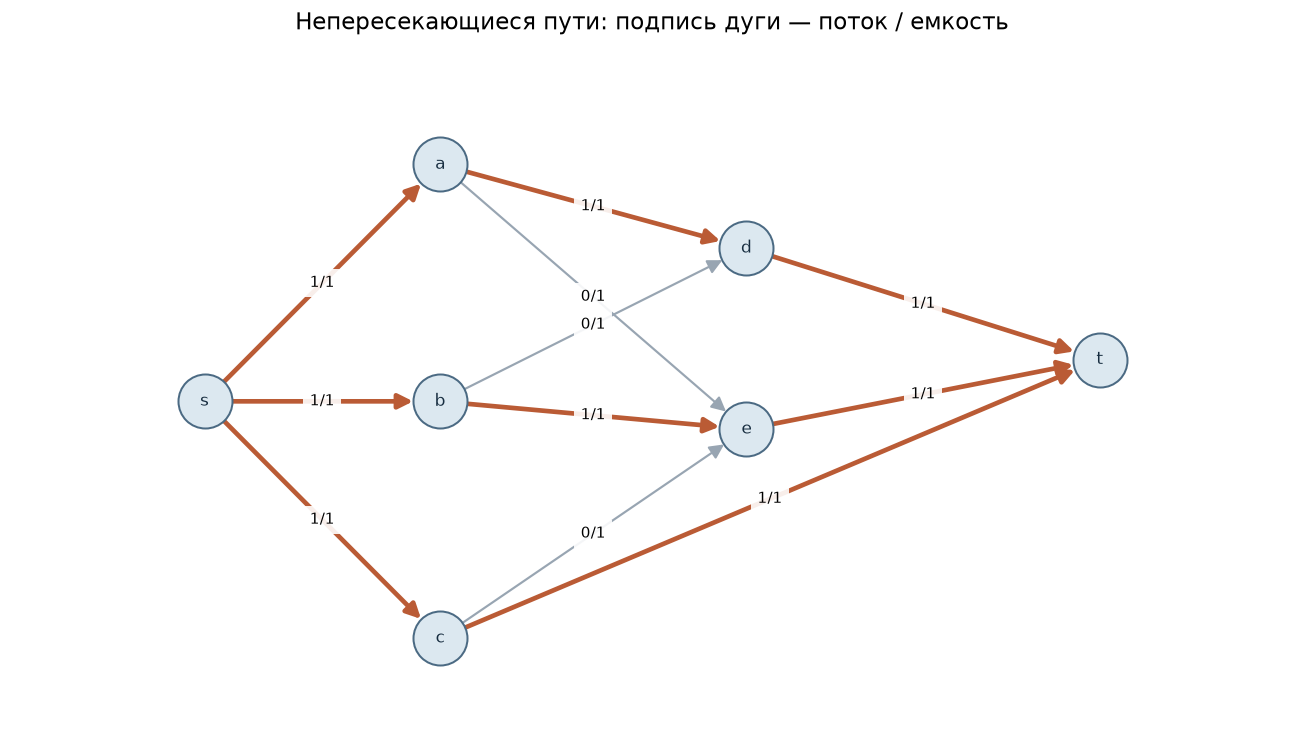

In [13]:
disjoint_graph = nx.DiGraph()
disjoint_edges = [
    ("s", "a"), ("s", "b"), ("s", "c"),
    ("a", "d"), ("a", "e"), ("b", "d"), ("b", "e"),
    ("c", "e"), ("c", "t"), ("d", "t"), ("e", "t"),
]
disjoint_graph.add_edges_from(disjoint_edges, capacity=1)
flow_value, edge_flow = nx.algorithms.flow.maximum_flow(
    disjoint_graph, "s", "t", capacity="capacity",
    flow_func=nx.algorithms.flow.edmonds_karp
)
cut_value, partition = nx.algorithms.flow.minimum_cut(
    disjoint_graph, "s", "t", capacity="capacity",
    flow_func=nx.algorithms.flow.edmonds_karp
)
source_side, sink_side = partition
cut_edges = [(u, v) for u, v in disjoint_graph.edges if u in source_side and v in sink_side]

positive_flow = nx.DiGraph()
positive_flow.add_nodes_from(disjoint_graph)
positive_flow.add_edges_from((u, v) for u, v in disjoint_graph.edges if edge_flow[u][v] > 0)
disjoint_paths = []
for _ in range(int(flow_value)):
    selected_path = nx.shortest_path(positive_flow, "s", "t")
    disjoint_paths.append(selected_path)
    positive_flow.remove_edges_from(zip(selected_path[:-1], selected_path[1:]))

display(pd.DataFrame([
    {"Дуга": f"{u} → {v}", "Емкость": 1, "Поток": edge_flow[u][v],
     "В минимальном разрезе": (u, v) in cut_edges}
    for u, v in disjoint_graph.edges
]))
display(pd.DataFrame([
    {"Номер пути": i, "Путь": " → ".join(path), "Число дуг": len(path) - 1}
    for i, path in enumerate(disjoint_paths, start=1)
]))
display(pd.DataFrame([{
    "Максимальный поток": int(flow_value), "Емкость минимального разреза": int(cut_value),
    "Сторона источника": ", ".join(sorted(source_side)),
    "Дуги разреза": "; ".join(f"{u} → {v}" for u, v in cut_edges),
}]))

used_edges = [(u, v) for path in disjoint_paths for u, v in zip(path[:-1], path[1:])]
cut_graph = disjoint_graph.copy()
cut_graph.remove_edges_from(cut_edges)
assert flow_value == cut_value == len(disjoint_paths) == 3
assert len(used_edges) == len(set(used_edges))
assert not nx.has_path(cut_graph, "s", "t")
assert all(path[0] == "s" and path[-1] == "t" for path in disjoint_paths)
assert all(0 <= edge_flow[u][v] <= 1 for u, v in disjoint_graph.edges)
for node in set(disjoint_graph) - {"s", "t"}:
    assert sum(edge_flow[u][node] for u in disjoint_graph.predecessors(node)) == sum(edge_flow[node].values())

disjoint_positions = {
    "s": (0, 0), "a": (1, 1.7), "b": (1, 0), "c": (1, -1.7),
    "d": (2.3, 1.1), "e": (2.3, -0.2), "t": (3.8, 0.3),
}
draw_graph(disjoint_graph, pos=disjoint_positions,
           edge_labels={(u, v): f"{edge_flow[u][v]}/1" for u, v in disjoint_graph.edges},
           highlight_edges=used_edges,
           title="Непересекающиеся пути: подпись дуги — поток / емкость")

### Ответ

1. Максимальное число непересекающихся по ребрам путей — **3**.
2. Например, подходят $s\to a\to d\to t$, $s\to b\to e\to t$, $s\to c\to t$. Фактически выделенные из потока пути приведены в таблице.
3. Разрез $S=\{s\}$ содержит три выходящие дуги и имеет емкость 3. Поэтому четвертый путь невозможен. Минимальный разрез, найденный алгоритмом, также имеет емкость 3; он может отличаться от этого разреза.

## Задача 4.10

### Условие

В 1927 году Карл Менгер доказал, что максимальное количество непересекающихся по ребрам путей $s$-$t$ равно минимальной мощности множества дуг, удаление которых разъединяет $s$ и $t$. Это частный случай результата, рассмотренного в Главе 4; какого именно?

### Дано

| Обозначение | Значение |
|:--|:--|
| $G=(V,E)$ | Конечный ориентированный граф |
| $s,t\in V$, $s\ne t$ | Источник и сток |
| $\lambda(s,t)$ | Максимальное число непересекающихся по ребрам путей |
| $\kappa_E(s,t)$ | Минимальное число дуг, удаление которых уничтожает все пути из $s$ в $t$ |
| $c_e=1$ | Вспомогательная пропускная способность каждой дуги |

### Теоретическое обоснование

Это следствие **теоремы Форда—Фалкерсона о максимальном потоке и минимальном разрезе** совместно с целочисленностью максимального потока при целых пропускных способностях. Для сети с $c_e=1$ теорема утверждает

$$F^*=\min_{S:\,s\in S,\ t\notin S}
\sum_{e\in\delta^+(S)}c_e
=\min_{S:\,s\in S,\ t\notin S}|\delta^+(S)|.$$

### Найти

Связь равенства $\lambda(s,t)=\kappa_E(s,t)$ с теоремой о максимальном потоке и минимальном разрезе.

### Решение

1. **От путей к потоку.** По каждому из $k$ непересекающихся по ребрам путей направим единицу потока. Ограничения емкости 1 и балансы в промежуточных вершинах выполняются. Получаем поток величины $k$, следовательно, $\lambda(s,t)\leq F^*$.

2. **От потока к путям.** При целых емкостях алгоритм Форда—Фалкерсона, начиная с нулевого потока, увеличивает его на целые величины и дает целочисленный максимальный поток. Его можно разложить на единичные пути и циклы. Удаление циклов не меняет величины потока. Оставшиеся $F^*$ путей не используют одну дугу совместно, поскольку ее емкость равна 1. Значит, $\lambda(s,t)\geq F^*$ и потому $\lambda(s,t)=F^*$.

3. **От разреза к разделяющему множеству.** Удаление всех дуг $\delta^+(S)$ любого $s$-$t$-разреза уничтожает все пути из $s$ в $t$. Обратно, пусть удаление множества дуг $D$ разъединяет $s$ и $t$. В оставшемся графе возьмем множество $S$ вершин, достижимых из $s$. Тогда $t\notin S$, а все исходные дуги из $S$ в $V\setminus S$ принадлежат $D$. Поэтому $|\delta^+(S)|\leq|D|$. Минимальная мощность разделяющего множества совпадает с минимальной мощностью разреза.

4. **Применение теоремы.** Максимальный поток равен минимальной емкости разреза; при единичных емкостях емкость равна числу дуг. Следовательно,

$$\boxed{\lambda(s,t)=F^*=\min_{S:\,s\in S,\ t\notin S}|\delta^+(S)|=\kappa_E(s,t).}$$

### Ответ

1. Утверждение Менгера о непересекающихся **по ребрам** путях — частный случай теоремы **о максимальном потоке и минимальном разрезе** для единичных пропускных способностей, с использованием целочисленности оптимального потока.
2. Если пути из $s$ в $t$ отсутствуют, обе величины равны нулю. Общее прохождение через промежуточные вершины разрешено: речь идет о реберной, а не вершинной версии теоремы.